This file is for calculating the final result from GRMHD simulations and EHT-Imaging.

What is needed:

- `GRMHD/grmhdDataAfterImageS.npy`
- `GRMHD/EVPA.npy`
- `NormR.csv`

# libraries, functions, ...

In [1]:
import numpy as np
from copy import deepcopy
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from utils.libanaly import Plot_Background,plot_quivers,CircleCalc,ImageS
from scipy.linalg import cho_factor, cho_solve

# Part GRMHD: calucate std or cor (without Axion)

What we get:

- `cor_grmhd` it is a number (rad) representing the standard deviation of different time GRMHD simulations

In [2]:
grmhdDataAfterImageS=np.load('./GRMHD/grmhdDataAfterImageS.npy')
EVPA=np.load('./GRMHD/EVPA.npy') #rad
EVPA_without_axion=EVPA[:,0,:,:]

In [3]:
P_without_axion=np.sqrt(grmhdDataAfterImageS[:,0,:,:,1]**2+grmhdDataAfterImageS[:,0,:,:,2]**2)

In [4]:
rg_per_pixel=0.51073125
condition2to9=np.array([[2<=np.sqrt((i-31.5)**2+(j-31.5)**2)*rg_per_pixel<=9 for j in range(64)] for i in range(64)])
threshold=0.1e9
def get_EVPA_diff_1day():
    start=1600
    end=3000
    grmhd_step=10
    step=30 # 30 * 0.1 *8h=1day
    r_step=step//grmhd_step
    

    diff=1

    evpa_diff_temp=np.zeros(((end-start)//grmhd_step-diff*r_step+1,64,64))
    evpa_diff_temp_with_condition=np.zeros(((end-start)//grmhd_step-diff*r_step+1,64,64))
    for num in range((end-start)//grmhd_step-diff*r_step+1):
        evpa_diff_temp[num]=CircleCalc.circle_sub_evpa(EVPA_without_axion[num+diff*r_step],EVPA_without_axion[num])
        condition=(P_without_axion[num+diff*r_step]>threshold) * (P_without_axion[num]>threshold) * condition2to9 # can be optimized
        evpa_diff_temp_with_condition[num]=evpa_diff_temp[num]*condition
        evpa_diff_temp_with_condition[num][evpa_diff_temp_with_condition[num]==0]=np.nan
    return evpa_diff_temp,evpa_diff_temp_with_condition


In [5]:
evpa_diff,evpa_diff_with_condition=get_EVPA_diff_1day()

In [6]:
def gaussian(x, amplitude, mean, stddev):
    return amplitude/np.sqrt(2*np.pi)/stddev * np.exp(-((x - mean) / stddev)**2 / 2)

def plot_gaussian1(data_temp,bins=100,plot_range=(-7,7),plot=True,initial_guess=[1, 0, 1],rm_nan=True,figsize=(16,16)):
    
    # 生成随机数据
    np.random.seed(42)
    data = deepcopy(data_temp)
    if rm_nan==True:
        data=data[np.isfinite(data)]
    

    # 生成直方图
    hist, bin_edges = np.histogram(data, bins=bins, density=True)
    bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2


    # 初始猜测值
    # initial_guess = initial_guess

    # 使用curve_fit进行拟合
    params, covariance = curve_fit(gaussian, bin_centers, hist, p0=initial_guess,maxfev=5000000)

    if plot==True:
        # 绘制直方图
        fig=plt.figure(figsize=figsize)
        plt.hist(data, bins=bins, density=True,range=plot_range,color='orange')

        # 绘制拟合曲线
        x_range = np.linspace(*plot_range, 100)
        fit_curve = gaussian(x_range, *params)
        # "$y="+f"{params[0]:.3f}"+r"\exp{\frac{x-"+f"{params[1]:.3f}"+r"^2}{2\cdot "+f"{params[2]:.3f}"+"^2}}$"
        plt.plot(x_range, fit_curve, 'r-', label=r"$P=\frac{A}{\sqrt{2\pi}\sigma} e^{-\frac{(x-x_0)^2}{2\sigma^2}}$ , "+f"$A={params[0]:.2f},\ x_0={params[1]:.2f},\ \sigma={params[2]:.2f}$",color='brown')
        plt.xticks(fontsize=24)
        plt.yticks(fontsize=24)
        # plt.xlabel(r"$\frac{\Delta I_{\left("+f"{day}"+r"\mathrm{day}\right)}}{I}$",fontsize=30)
        # plt.xlabel(r"$\Delta EVPA _{\left("+f"{day}"+r"\mathrm{day}\right)}$",fontsize=24)
        plt.gca().spines['top'].set_visible(False)
        plt.gca().spines['right'].set_visible(False)
        plt.legend(fontsize=24)
        plt.show()
    
    return params,covariance

<>:33: SyntaxWarning: invalid escape sequence '\ '
<>:33: SyntaxWarning: invalid escape sequence '\ '
<>:33: SyntaxWarning: invalid escape sequence '\ '
<>:33: SyntaxWarning: invalid escape sequence '\ '
/tmp/ipykernel_1788613/3984944986.py:33: SyntaxWarning: invalid escape sequence '\ '
  plt.plot(x_range, fit_curve, 'r-', label=r"$P=\frac{A}{\sqrt{2\pi}\sigma} e^{-\frac{(x-x_0)^2}{2\sigma^2}}$ , "+f"$A={params[0]:.2f},\ x_0={params[1]:.2f},\ \sigma={params[2]:.2f}$",color='brown')
/tmp/ipykernel_1788613/3984944986.py:33: SyntaxWarning: invalid escape sequence '\ '
  plt.plot(x_range, fit_curve, 'r-', label=r"$P=\frac{A}{\sqrt{2\pi}\sigma} e^{-\frac{(x-x_0)^2}{2\sigma^2}}$ , "+f"$A={params[0]:.2f},\ x_0={params[1]:.2f},\ \sigma={params[2]:.2f}$",color='brown')


In [ ]:
evpa_diff_with_condition[:,32:,20:40]=

(138, 64, 64)

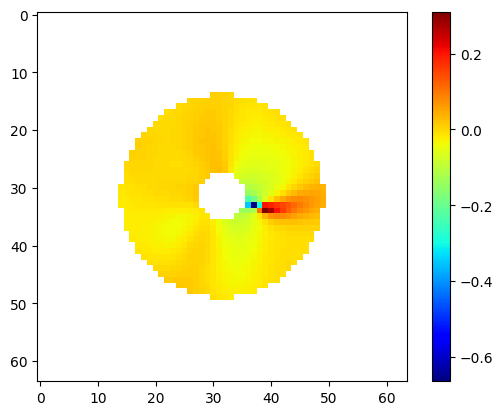

In [14]:
plt.imshow(evpa_diff_with_condition[0],cmap='jet')
plt.colorbar()

/tmp/ipykernel_1788613/3984944986.py:33: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "r-" (-> color='r'). The keyword argument will take precedence.
  plt.plot(x_range, fit_curve, 'r-', label=r"$P=\frac{A}{\sqrt{2\pi}\sigma} e^{-\frac{(x-x_0)^2}{2\sigma^2}}$ , "+f"$A={params[0]:.2f},\ x_0={params[1]:.2f},\ \sigma={params[2]:.2f}$",color='brown')


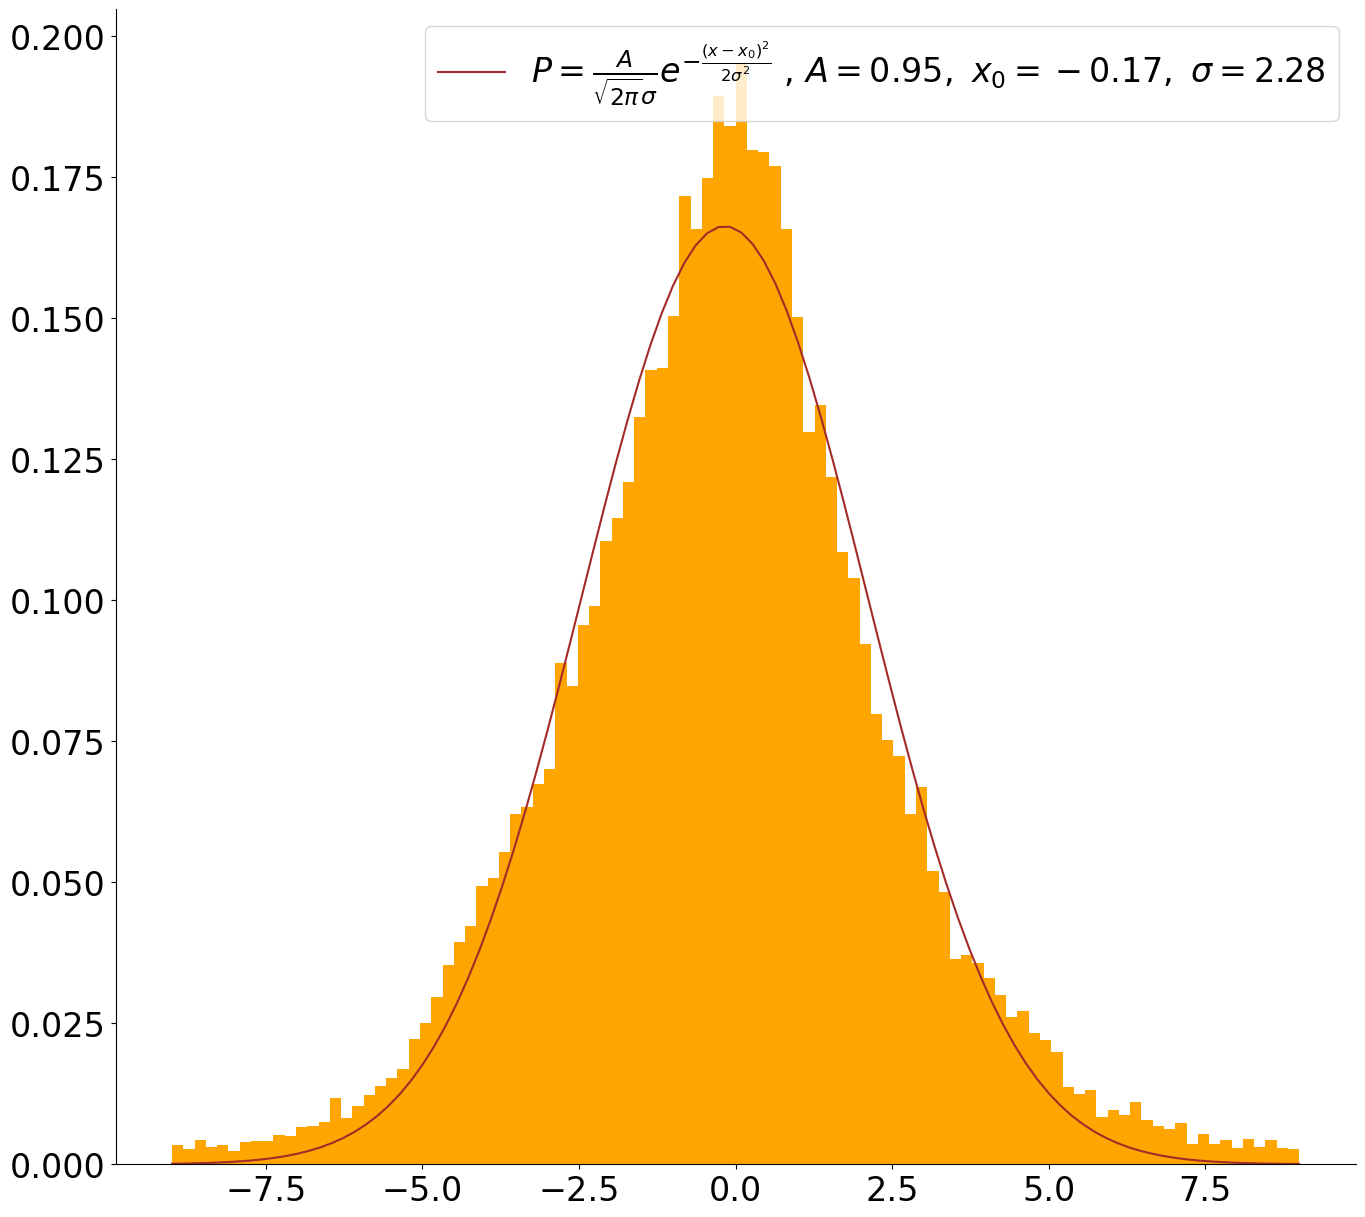

(array([ 0.94956985, -0.17434092,  2.27787248]),
 array([[ 1.10732837e-04, -2.23785825e-14,  1.77086408e-04],
        [-2.23785825e-14,  8.49601434e-04, -3.43966918e-11],
        [ 1.77086408e-04, -3.43966918e-11,  8.49601514e-04]]))

In [19]:
plot_gaussian1(evpa_diff_with_condition[:,:32,32:].reshape(-1,1)[:,0]/np.pi*180,bins=100,plot_range=(-9,9),plot=True,initial_guess=[1, 0, 1], rm_nan=True,figsize=(16,15))

/tmp/ipykernel_1788613/3984944986.py:33: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "r-" (-> color='r'). The keyword argument will take precedence.
  plt.plot(x_range, fit_curve, 'r-', label=r"$P=\frac{A}{\sqrt{2\pi}\sigma} e^{-\frac{(x-x_0)^2}{2\sigma^2}}$ , "+f"$A={params[0]:.2f},\ x_0={params[1]:.2f},\ \sigma={params[2]:.2f}$",color='brown')


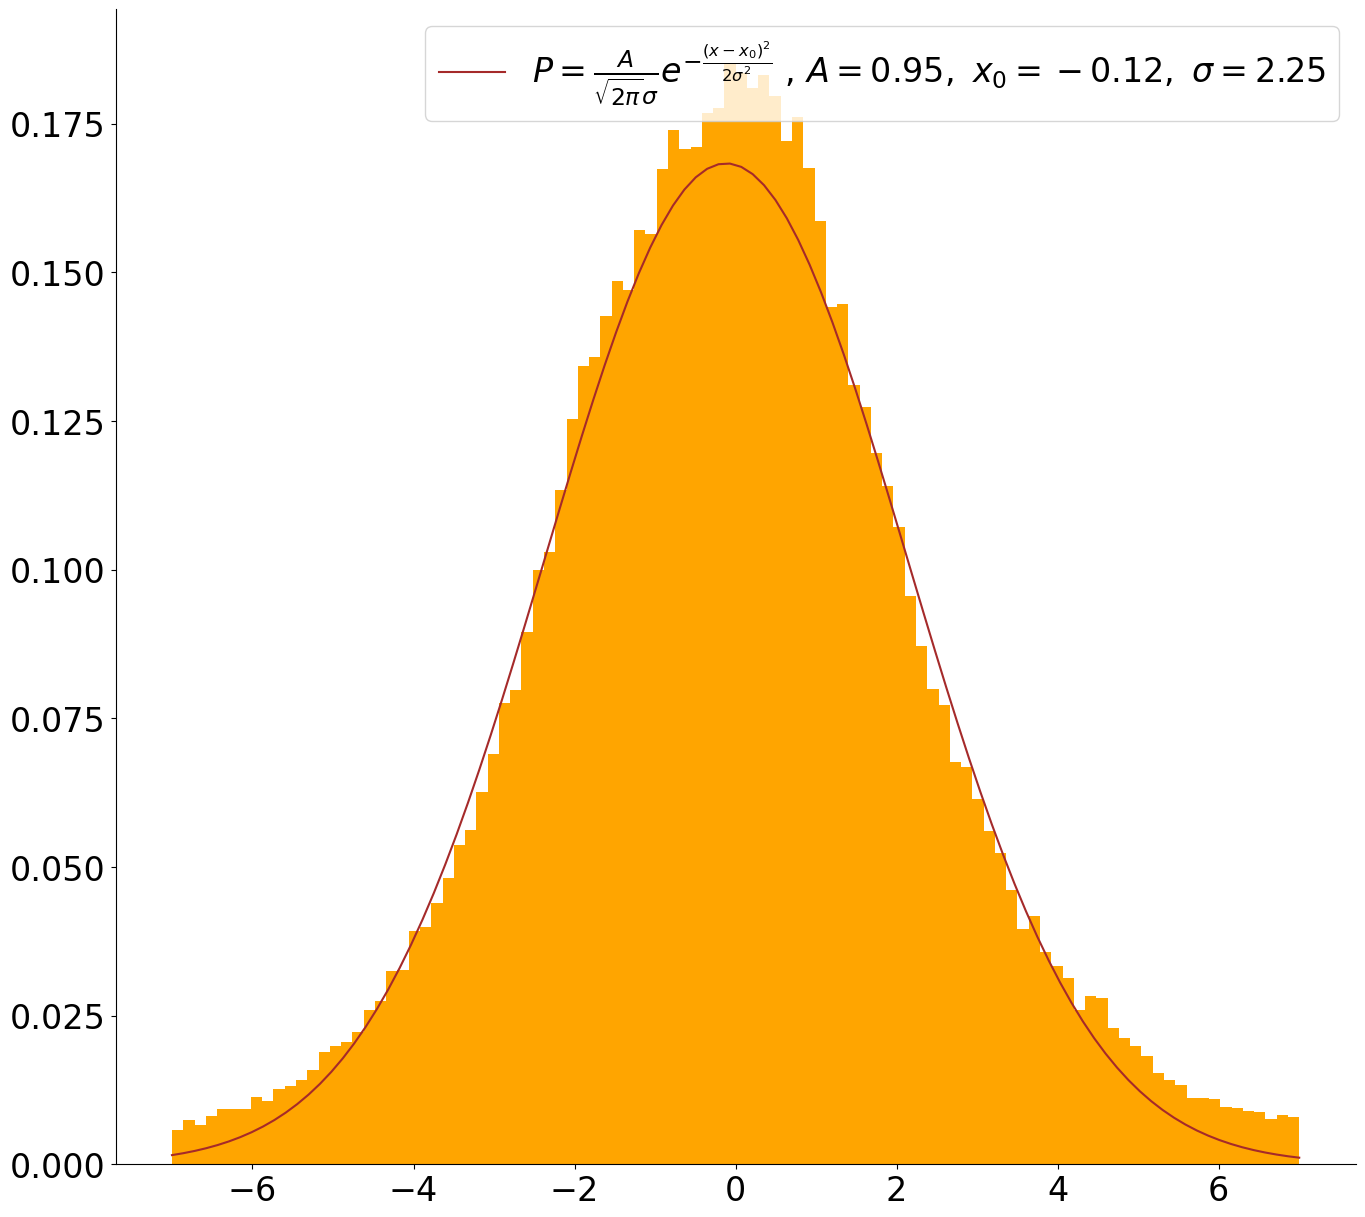

(array([ 0.94766657, -0.11842487,  2.24592088]),
 array([[3.83293469e-05, 2.92571225e-10, 6.05569988e-05],
        [2.92571225e-10, 2.87046431e-04, 1.48484774e-09],
        [6.05569988e-05, 1.48484774e-09, 2.87032008e-04]]))

In [7]:
plot_gaussian1(evpa_diff_with_condition.reshape(-1,1)[:,0]/np.pi*180,bins=100,plot_range=(-7,7),plot=True,initial_guess=[1, 0, 1], rm_nan=True,figsize=(16,15))

In [39]:
cor_grmhd=np.identity(64*64)*(2.24592088/180*np.pi)**2

# Part Axion

In [40]:
omega_grmhd=0.4 # check it
axion_norm=0.1 # check it
g_res=40
gagg = np.logspace(np.log10(1/137.),2,g_res)

In [41]:
EVPA_fit_result=np.load('./GRMHD/EVPA_fit_result.npy') # rad

我们没有跑不同omega下的axion随grmhd演化的效应。因此需要把在omega=0.4情况下的diffs_axion_evpa结果rescale到所有的情况。使用不同omega时photon ring的半径上的axion强度来rescale。

In [42]:
import pandas as pd
from scipy.interpolate import RegularGridInterpolator

def load_and_interpolate(csv_file):
    # 读取CSV文件
    df = pd.read_csv(csv_file, header=None, names=["omega", "R", "f"])
    
    # 获取唯一的omega和R值
    omega_values = np.unique(df["omega"].values)
    R_values = np.unique(df["R"].values)
    
    # 创建二维插值网格
    f_values = df.pivot(index="omega", columns="R", values="f").values
    
    # 创建插值函数
    interpolator = RegularGridInterpolator((omega_values, R_values), f_values, bounds_error=False, fill_value=None)
    
    def _f(omega, R):
        # 计算插值
        return interpolator((omega, R))

    return _f

In [43]:
R_photon_ring=(246-157)/400*2*23.1131/2

In [44]:
f_axion_norm=load_and_interpolate("NormR.csv")

## every pixel, find sigma of diffs_axion_evpa over every grmhd

In [45]:
extra_phase=np.linspace(0,2*np.pi,16)


# 2*amp*np.sin(0.112411*omega/2*24)*np.sin(0.112411*omega/2*6)/(0.112411*omega/2*6)*np.sin(ep+phi0)/axion_norm*gagg[g]   
# first calc 2*amp*np.sin(0.112411*omega/2*24)*np.sin(0.112411*omega/2*6)/(0.112411*omega/2*6)*np.sin(ep+phi0)/axion_norm
# and define 2*np.sin(0.112411*omega/2*24)*np.sin(0.112411*omega/2*6)/(0.112411*omega/2*6)/axion_norm

condition=(P_without_axion>threshold) * condition2to9 # ?*64*64 and 64*64

# caution!!! amp should be set
constant1_axion=2*np.sin(0.112411*omega_grmhd/2*24)*np.sin(0.112411*omega_grmhd/2*6)/(0.112411*omega_grmhd/2*6)/axion_norm

diffs_axion_evpa_t=np.zeros((16,EVPA_fit_result.shape[1],EVPA_fit_result.shape[2]))
diffs_axion_evpa_std_t=np.zeros((16,EVPA_fit_result.shape[1],EVPA_fit_result.shape[2]))

A_data_list=deepcopy(EVPA_fit_result[:,:,:,0])*condition
A_data_list[A_data_list==0]=np.nan
phi0_data_list=deepcopy(EVPA_fit_result[:,:,:,1])*condition
phi0_data_list[phi0_data_list==0]=np.nan

In [46]:
def fit_gaussian(data_list,bins_list=[40,30,20],initial_guess=[1,0,1],rm_nan=False,maxfev=5000000,output=True):
    _data=deepcopy(data_list)
    if rm_nan==True:
        _data=_data[np.isfinite(_data)]
        
    fit_success=False
    
    if output:
        print("------------------fit start-----------------------")
    
    for bins in bins_list:
        if _data.shape[0]<bins:
            if output:
                print("badfit, bins>len(data)")
            continue
        hist,bin_edges=np.histogram(_data,bins=bins)
        bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2
        initial_guess[0]=np.shape(_data)[0]
        initial_guess[1]= bin_centers[np.argmax(hist)]
        initial_guess[2]=np.std(_data)
        try:
            params, covariance = curve_fit(gaussian, bin_centers, hist, p0=initial_guess,maxfev=maxfev)
        except Exception as e:
            if output:
                print("badfit, error",e)
            continue
        # params=np.asarray(params)
        # covariance=np.asarray(covariance)
        c1=abs(covariance[1][1])/abs(params[1])
        c2=abs(covariance[2][2])/abs(params[2])
        if output:
            print(c1,c2)
        if c1<1 and c2<1:
            fit_success=True
            break
        else:
            if output:
                print("badfit, cov")
    if not fit_success:
        params=np.zeros((3))
        covariance=np.zeros((3,3))
        params[:]=np.nan
        covariance[:]=np.nan
    if output:
        print("fit complete!")
    return params, covariance

def fit_gaussian_params(data_list,bins_list=[40,30,20],initial_guess=[1,0,1],rm_nan=False,maxfev=5000000,output=True):
    params,_=fit_gaussian(data_list,bins_list=bins_list,initial_guess=initial_guess,rm_nan=rm_nan,maxfev=maxfev,output=output)
    return params

In [47]:
# 4min
# A_params=np.apply_along_axis(fit_gaussian_params,0,A_data_list,rm_nan=True)
# phi0_params=np.apply_along_axis(fit_gaussian_params,0,phi0_data_list,rm_nan=True) # change it 



In [48]:
# np.save("A_params",A_params)
# np.save("phi0_params",phi0_params)
A_params=np.load("A_params.npy") # amplitude, mean, stddev
phi0_params=np.load("phi0_params.npy")

In [49]:
amp=EVPA_fit_result[51,:,:,0]
phi0=EVPA_fit_result[51,:,:,1]
for i in range(extra_phase.shape[0]):
    ep=extra_phase[i]
    diffs_axion_evpa_t[i]=constant1_axion*amp*np.sin(ep+phi0)   # *gagg[g]
    diffs_axion_evpa_std_t[i]=np.sqrt(np.power(constant1_axion*np.sin(ep+phi0)*A_params[2],2)+np.power(constant1_axion*amp*np.cos(ep+phi0)*phi0_params[2],2))
diffs_axion_evpa=np.mean(diffs_axion_evpa_t,axis=0) # rad
diffs_axion_evpa_std=np.mean(diffs_axion_evpa_std_t,axis=0) # rad

In [50]:
A_params.shape

(3, 64, 64)

In [51]:
np.save("./Plot/diffs_axion_evpa_std.npy",diffs_axion_evpa_std)

In [52]:
np.save("./Plot/diffs_axion_evpa.npy",diffs_axion_evpa)

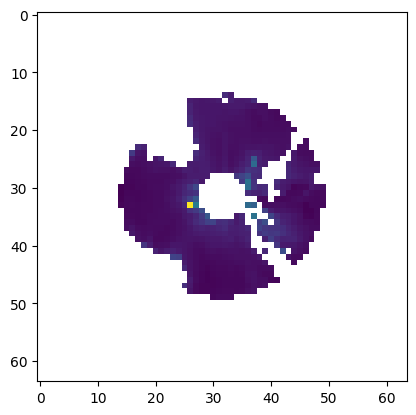

In [53]:
plt.imshow(diffs_axion_evpa_std)


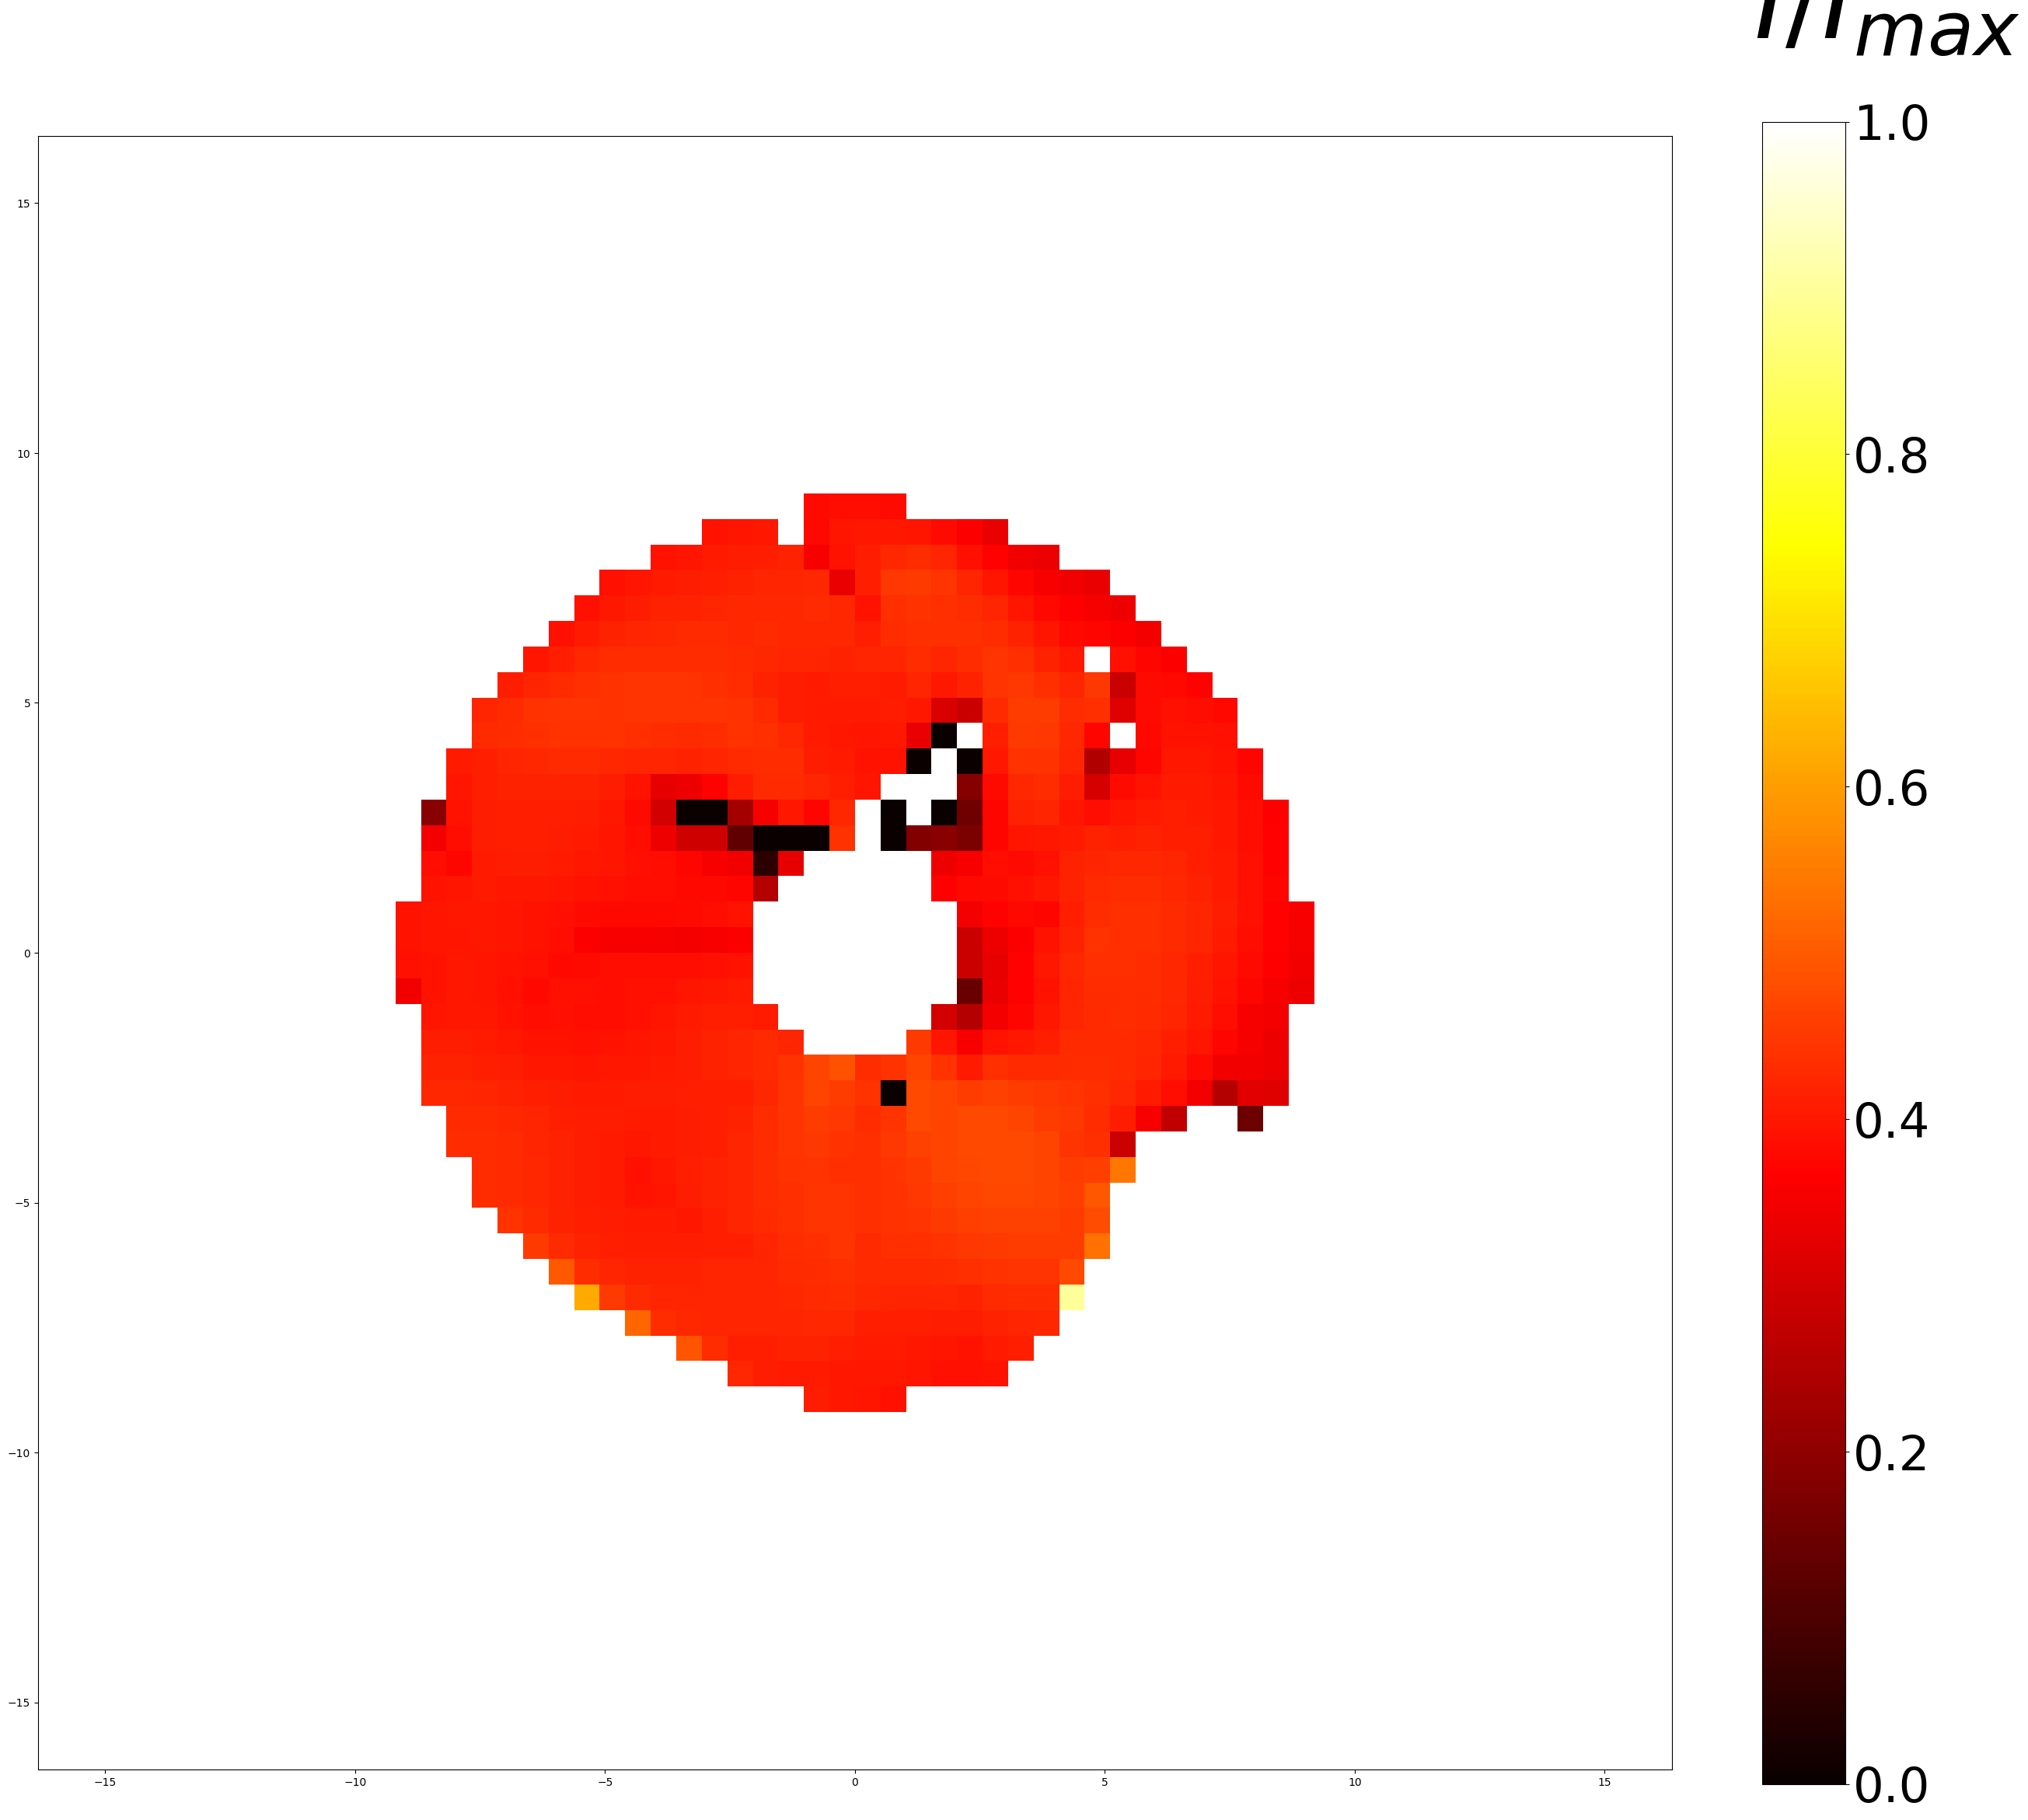

In [54]:
figure,ax=plt.subplots(figsize=(30,30))
Plot_Background(figure,ax,A_params[1]/np.pi*180)

1d

In [55]:
# 141,360,3
EVPA_fit_result_1d=np.load('./GRMHD/EVPA_fit_result_1d.npy') # rad


In [56]:
diffs_axion_evpa_t_1d=np.zeros((16,EVPA_fit_result_1d.shape[1]))
diffs_axion_evpa_std_t_1d=np.zeros((16,EVPA_fit_result_1d.shape[1]))

A_data_list_1d=deepcopy(EVPA_fit_result_1d[:,:,0])
A_data_list_1d[A_data_list_1d==0]=np.nan
phi0_data_list_1d=deepcopy(EVPA_fit_result_1d[:,:,1])
phi0_data_list_1d[phi0_data_list_1d==0]=np.nan

In [57]:
# 2min
# A_params_1d=np.apply_along_axis(fit_gaussian_params,0,A_data_list_1d,rm_nan=True)
# phi0_params_1d=np.apply_along_axis(fit_gaussian_params,0,phi0_data_list_1d,rm_nan=True) # change it 

In [58]:
# np.save("A_params_1d",A_params_1d)
# np.save("phi0_params_1d",phi0_params_1d)
A_params_1d=np.load("A_params_1d.npy") # amplitude, mean, stddev
phi0_params_1d=np.load("phi0_params_1d.npy")

In [59]:
amp_1d=EVPA_fit_result_1d[51,:,0]
phi0_1d=EVPA_fit_result_1d[51,:,1]
for i in range(extra_phase.shape[0]):
    ep=extra_phase[i]
    diffs_axion_evpa_t_1d[i]=constant1_axion*amp_1d*np.sin(ep+phi0_1d)   # *gagg[g]
    diffs_axion_evpa_std_t_1d[i]=np.sqrt(np.power(constant1_axion*np.sin(ep+phi0_1d)*A_params_1d[2],2)+np.power(constant1_axion*amp_1d*np.cos(ep+phi0_1d)*phi0_params_1d[2],2))
diffs_axion_evpa_1d=np.mean(diffs_axion_evpa_t_1d,axis=0) # rad
diffs_axion_evpa_std_1d=np.mean(diffs_axion_evpa_std_t_1d,axis=0) # rad

# EXPERIMENT

In [60]:

import pickle
import numpy as np
import matplotlib
import os
import argparse
import numpy as np
from copy import deepcopy
from scipy.interpolate import griddata, interp2d
from scipy import integrate, optimize
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter

def plotting_script(xarray,yarray,name = 'test'):
    plt.clf()
    fig,ax = plt.subplots(figsize=(12,9))
    ax.set_xscale('log')
    ax2 = ax.twiny()
    ax2.set_xscale('log')
    ax2.set_ylim(-2,6)
    ax.set_yticks([-2,-1,0,1,2,3,4,5,6])
    ax.set_yticklabels(['-2','-1','0','1','2','3','4','5','6'],size=20)
    ax.set_ylabel('$\log_{10}(c)$',size=30)
    ax2.set_xticks([0.1,0.45])
    ax2.set_xticklabels(['0.1','0.45'],size=20)
    ax2.set_xlabel(r'$ \alpha $',size=30)
    ax2.set_xlim(0.0486495,4.86495)
    ax.set_xlim(1E-19, 1E-21)
    ax.set_xticks([1E-21,1E-20,1E-19])
    ax.set_xticklabels(['-21','-20','-19'],size=20)
    ax.set_xlabel('$\log_{10}(m_a/\mathrm{eV})$',size=30)
    ax2.plot(xarray,yarray,'black')
    ax2.plot([np.max(xarray),np.max(xarray)],[yarray[-1],6],'black')
    ax2.plot([np.min(xarray),np.min(xarray)],[yarray[0],6],'black')

    xcolor = ['SkyBlue','#C8C8A9','#FE4365']
    ax2.fill_between(xarray,yarray, 6,ls='-',lw=2,fc = xcolor[0],alpha=1)
    plt.savefig(f'M_all/new_static/{name}.pdf',dpi=600)




def get_inv(M):
    u,s,v = np.linalg.svd(M)
    return np.dot(u/s,u.T)

<>:22: SyntaxWarning: invalid escape sequence '\l'
<>:30: SyntaxWarning: invalid escape sequence '\l'
<>:22: SyntaxWarning: invalid escape sequence '\l'
<>:30: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_681590/1745484444.py:22: SyntaxWarning: invalid escape sequence '\l'
  ax.set_ylabel('$\log_{10}(c)$',size=30)
/tmp/ipykernel_681590/1745484444.py:30: SyntaxWarning: invalid escape sequence '\l'
  ax.set_xlabel('$\log_{10}(m_a/\mathrm{eV})$',size=30)


# Final

In [61]:
import scipy.stats as stats

In [62]:
def vonmises_mean(d1evpaarr):
    # d1evpaarr is from -0.5pi to 0.5pi
    kappa_fit, mu_fit ,_= stats.vonmises.fit(d1evpaarr*2)  # 只拟合 kappa 和 mu
    return mu_fit/2
    

In [63]:
def topset_rank(data_cor,data_std):
    sum_of_pixels=np.zeros(1572)
    for i in range(4):
        rmnan_times=np.nan_to_num(data_cor[i]/data_std[i].reshape(4096,1),nan=0)
        sum_of_pixels+=np.sum(((rmnan_times)[np.where(condition2to9.reshape(4096))])**2,axis=0)
    return sum_of_pixels

In [64]:
theta_mean = []
theta_std =[]
P_mean = []
I_mean = []
theta_cor = []
badset =[]
theta_data_vonmises_list=[]
resolution = 64
xy_coord = [(i,j) for i in range(resolution) for j in range(resolution)]

def circleCenter(d1evpaarr):

    _, mu_fit ,_= stats.vonmises.fit(d1evpaarr*2)
    return mu_fit/2

num=0
data_cor_list=[]
for day in [95,96,100,101]:
    with np.load(f'./EHT-Imaging/{day}.npz') as data:
        theta_mean.append(data['arr_0']) # rad
        theta_std.append(data['arr_1']) # rad
        P_mean.append(data['arr_2']*6.54737E12) # ?这个哪来的
        # I_mean.append(data['arr_3']*6.54737E12)
        # P_mean.append(data['arr_2'])
    
    All_data=np.load(f'./EHT-Imaging/{day}_all_data.npy')
    theta_data=0.5*np.arctan2(All_data[:,:,:,2],All_data[:,:,:,1]) # rad
    theta_vonmises_mean=np.apply_along_axis(vonmises_mean,0,theta_data)
    theta_data_vonmises_list.append(CircleCalc.circle_sub_evpa(theta_data,theta_vonmises_mean)+theta_vonmises_mean)

    theta_data=CircleCalc.circle_sub_evpa(theta_data,theta_mean[num])+theta_mean[num]
    # theta_data=theta_data*180./np.pi # degree

    data_cor = np.zeros((64*64,All_data.shape[0]))
    for x in range(len(xy_coord)):
        i,j = xy_coord[x]
        if theta_mean[num][i][j] == 0 and theta_std[num][i][j] == 0 or np.isnan(theta_mean[num][i][j]) or np.isnan(theta_std[num][i][j]):
            badset.append(i*resolution+j)
        # data_cor[x] = (theta_data[i][j]-theta_mean[num][i][j])
        if np.isfinite(theta_mean[num][i][j]):
            pass
        data_cor[x] = CircleCalc.circle_sub_evpa(theta_data[:,i,j],theta_mean[num][i,j])
    data_cor_list.append(data_cor)
    num+=1

sum_of_pixels = topset_rank(data_cor_list,theta_std)

for num in range(4):

    # cor_data = np.dot(data_cor_list[num],data_cor_list[num].T)/All_data.shape[0]
    cor_data = np.dot(data_cor_list[num][:,np.argsort(sum_of_pixels)[:786]],data_cor_list[num][:,np.argsort(sum_of_pixels)[:786]].T)/786

    theta_cor.append(cor_data)

 
    

/tmp/ipykernel_681590/943259403.py:4: RuntimeWarning: invalid value encountered in divide
  rmnan_times=np.nan_to_num(data_cor[i]/data_std[i].reshape(4096,1),nan=0)


In [65]:
def gaussian2(x,*param):
    mean = param[0]
    sigma = param[1]
    amplitude = param[2]
    return amplitude/np.sqrt(2.*np.pi*sigma*sigma)*np.exp(-np.power(x-mean,2.)/2./sigma/sigma)

In [66]:
def fit_gaussian2(d1evpaarr,bins_i=4):
    counts,bins = np.histogram(d1evpaarr,bins=10*bins_i) #10*(4)
    #counts,bins =re_loc(counts,bins)
    xarray = np.array([(bins[i]+bins[i+1])/2 for i in range(len(bins)-1)])
    try:
        popt,pcov = optimize.curve_fit(gaussian2,xarray,counts,p0=[vonmises_mean(d1evpaarr),1,786]) #,maxfev=50000,gtol=1e-10
    except Exception as e:
        print(f'badfit, error',e)
        return np.array([np.nan,np.nan,np.nan])
    if abs(pcov[0][0])>abs(popt[0]) or abs(pcov[1][1])>abs(popt[1]):
        print(f'badfit')
        return np.array([np.nan,np.nan,np.nan])
    else:
        return np.array([popt[0],np.abs(popt[1]),popt[2]])

In [67]:
std_786=[]
mean_786=[]
theta_cor = []
for num in range(4):
    print(num)
    theta_data_786=theta_data_vonmises_list[num].reshape(1572,4096).T[:,np.argsort(sum_of_pixels)[:786]]
    tmpres=np.apply_along_axis(fit_gaussian2,1,theta_data_786)
    mean_786.append(tmpres[:,0])
    std_786.append(tmpres[:,1])
    cor_data=CircleCalc.circle_sub_evpa(theta_data_786.T,tmpres[:,0]).T
    theta_cor.append(np.dot(cor_data,cor_data.T)/786)


0
badfit
badfit
badfit, error Optimal parameters not found: Number of calls to function has reached maxfev = 800.
badfit, error Optimal parameters not found: Number of calls to function has reached maxfev = 800.
badfit
badfit, error Optimal parameters not found: Number of calls to function has reached maxfev = 800.
badfit, error Optimal parameters not found: Number of calls to function has reached maxfev = 800.
badfit
badfit, error Optimal parameters not found: Number of calls to function has reached maxfev = 800.
badfit, error Optimal parameters not found: Number of calls to function has reached maxfev = 800.
badfit, error Optimal parameters not found: Number of calls to function has reached maxfev = 800.
badfit
badfit
badfit
badfit
badfit, error Optimal parameters not found: Number of calls to function has reached maxfev = 800.
badfit
badfit, error Optimal parameters not found: Number of calls to function has reached maxfev = 800.
badfit
badfit
badfit
badfit, error Optimal parameters

In [68]:
np.isnan(std_786[2]).sum()

np.int64(513)

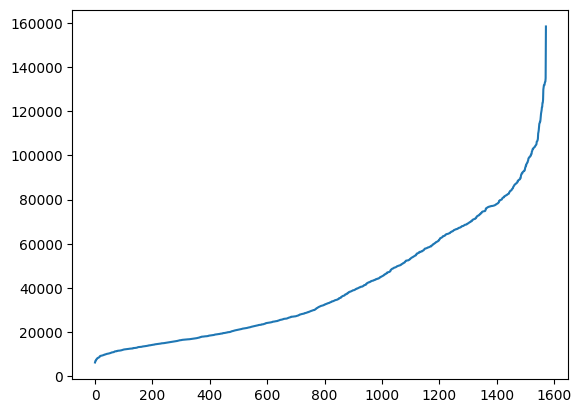

In [69]:
plt.plot(sum_of_pixels[np.argsort(sum_of_pixels)])

In [70]:
theta_mean[2].reshape(-1)[45*64+31]

np.float64(-1.0578655762335527)

In [71]:
mean_786[2][45*64+31]

np.float64(-1.0449415431575129)

/tmp/ipykernel_681590/3984944986.py:33: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "r-" (-> color='r'). The keyword argument will take precedence.
  plt.plot(x_range, fit_curve, 'r-', label=r"$P=\frac{A}{\sqrt{2\pi}\sigma} e^{-\frac{(x-x_0)^2}{2\sigma^2}}$ , "+f"$A={params[0]:.2f},\ x_0={params[1]:.2f},\ \sigma={params[2]:.2f}$",color='brown')


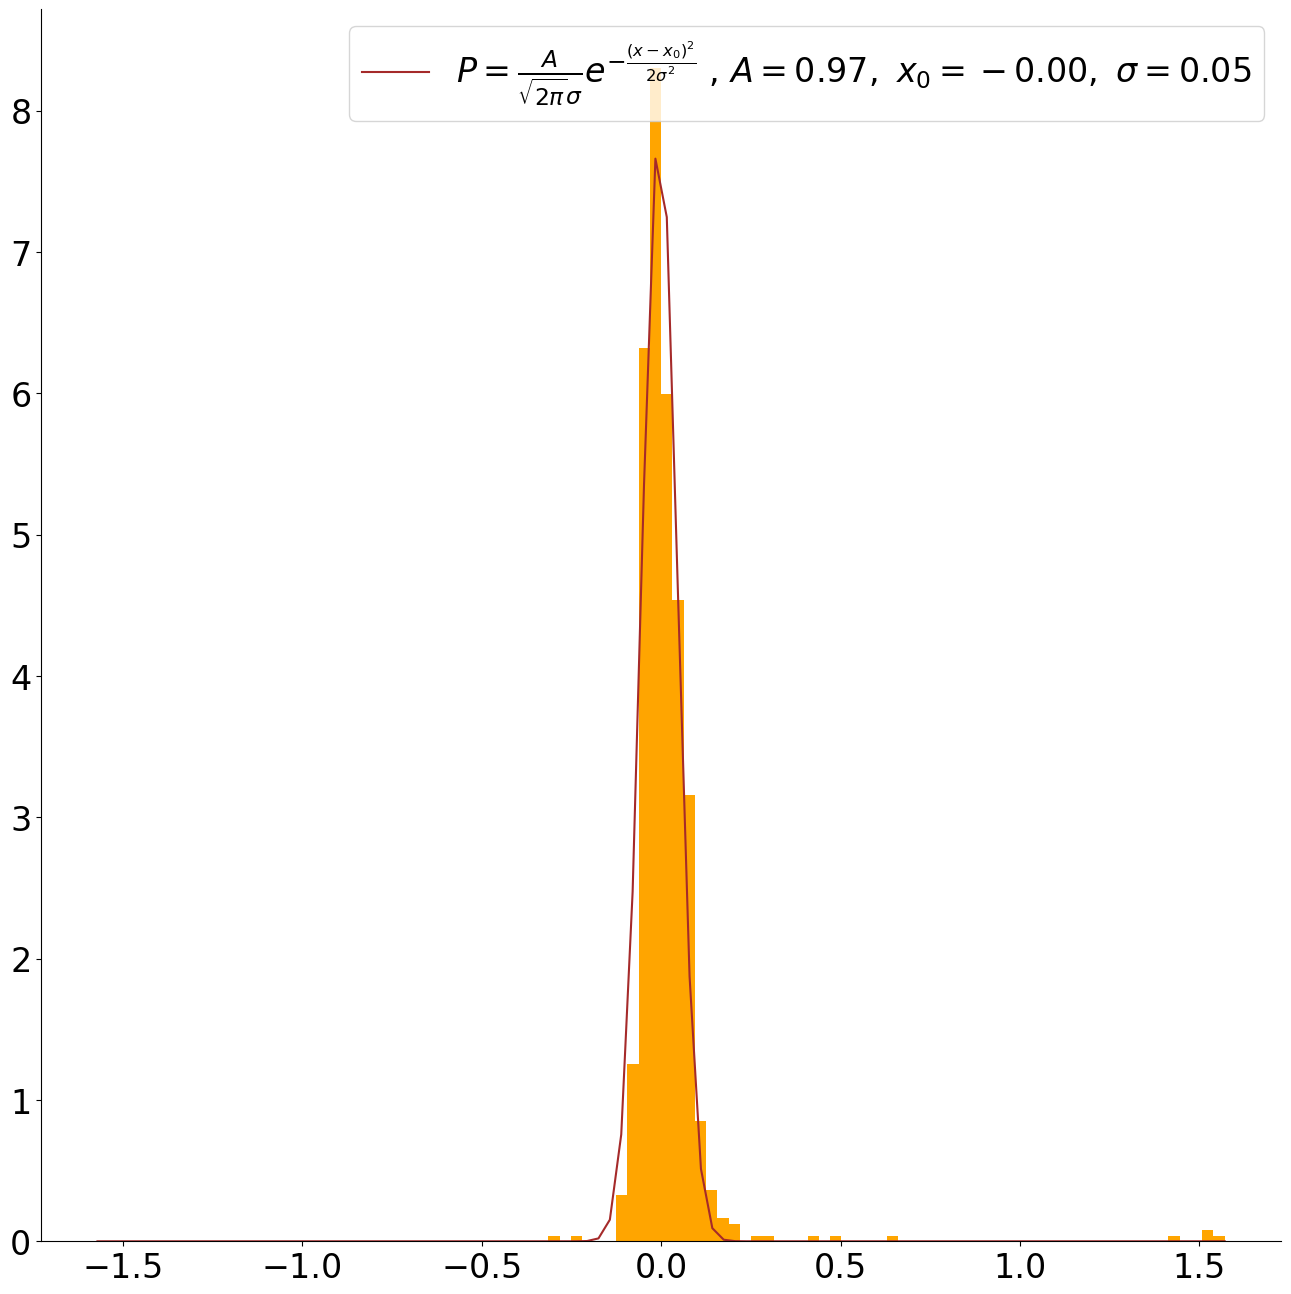

(array([ 0.97383608, -0.00425528,  0.04933193]),
 array([[7.14100088e-04, 1.05886033e-12, 2.41164043e-05],
        [1.05886033e-12, 2.44335920e-06, 4.53911500e-14],
        [2.41164043e-05, 4.53911500e-14, 2.44335896e-06]]))

In [72]:
plot_gaussian1(data_cor_list[3][45*64+31][np.argsort(sum_of_pixels)[:786]],100,plot_range=(-np.pi/2,np.pi/2),)

In [73]:
def fastxtMinvx(x,M):
    L = cho_factor(M, lower=True)
    y = cho_solve(L, x)
    return np.dot(x,y)

In [74]:
f_axion_norm(0.1,R_photon_ring)/f_axion_norm(0.45,R_photon_ring)

np.float64(0.06214278967349317)

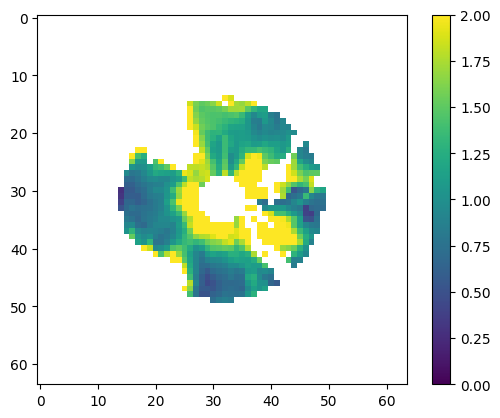

In [75]:
plt.imshow(diffs_axion_evpa_std/np.pi*180)
plt.colorbar()
plt.clim(0,2)

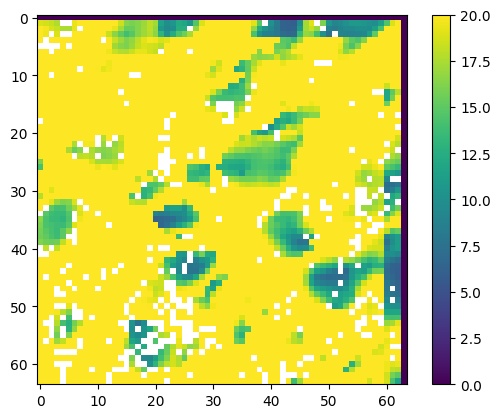

In [76]:
plt.imshow(np.sqrt(theta_std[3]*theta_std[3]+theta_std[2]*theta_std[2])/np.pi*180)
plt.colorbar()
plt.clim(0,20)

In [77]:
if not os.path.exists('Results/figure'):
    os.makedirs('Results/figure')
if not os.path.exists('Results/data'):
    os.makedirs('Results/data')

/tmp/ipykernel_681590/3984944986.py:33: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "r-" (-> color='r'). The keyword argument will take precedence.
  plt.plot(x_range, fit_curve, 'r-', label=r"$P=\frac{A}{\sqrt{2\pi}\sigma} e^{-\frac{(x-x_0)^2}{2\sigma^2}}$ , "+f"$A={params[0]:.2f},\ x_0={params[1]:.2f},\ \sigma={params[2]:.2f}$",color='brown')


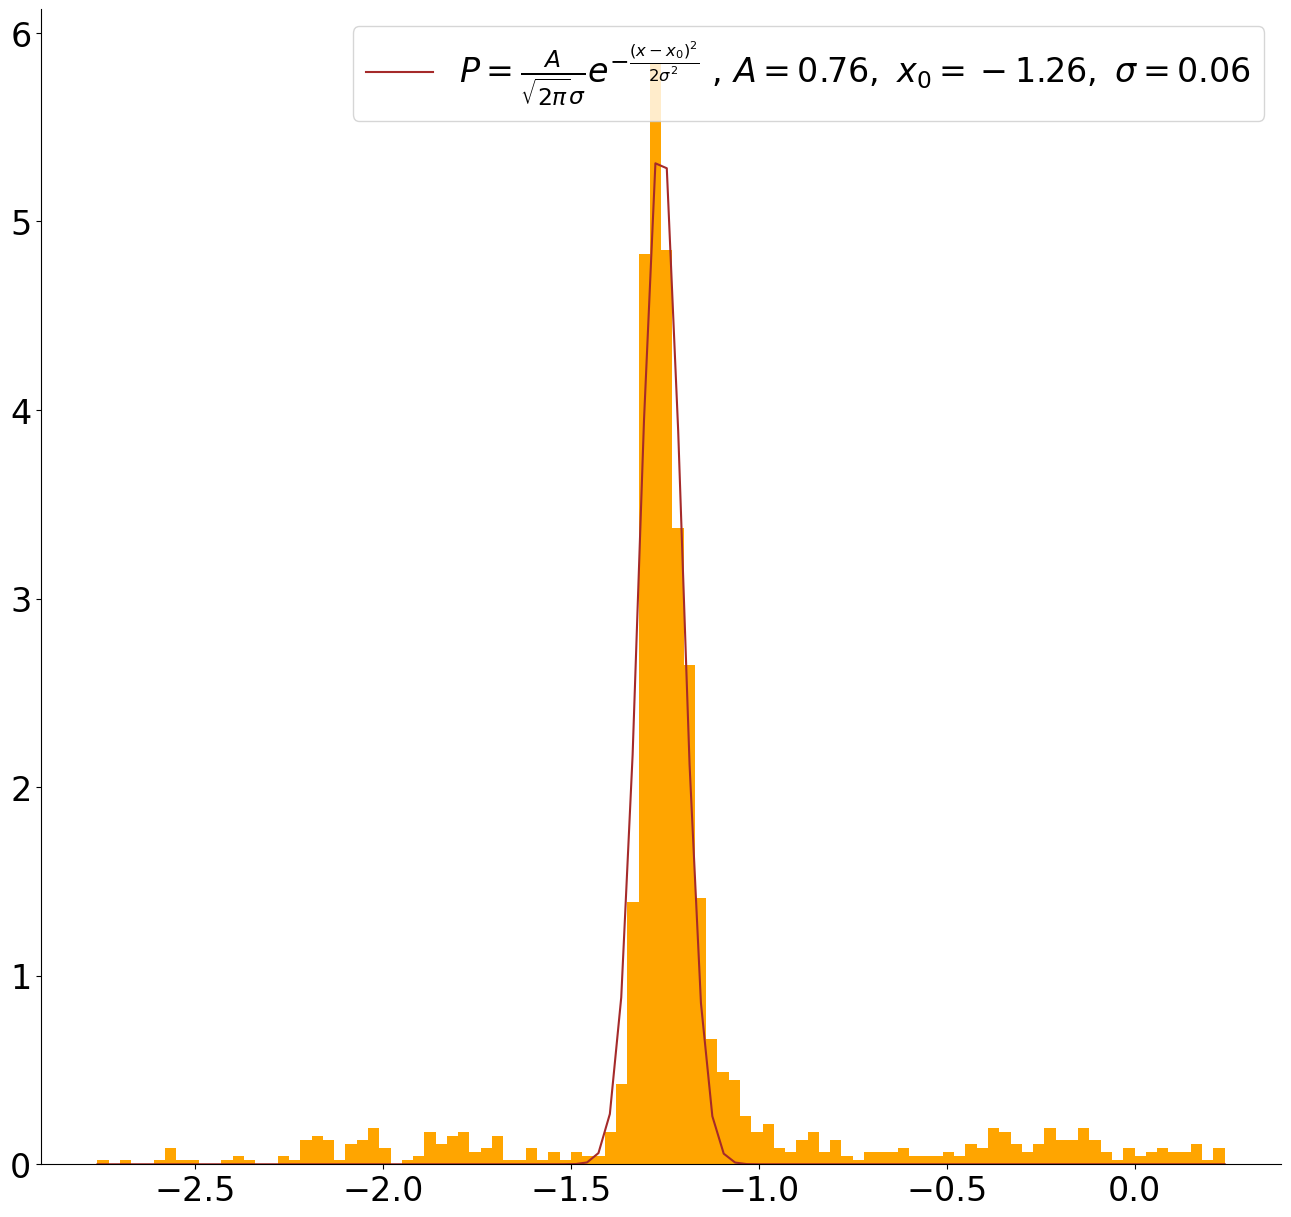

(array([ 0.76118142, -1.26049871,  0.05522948]),
 array([[ 4.06529984e-04, -2.63238052e-15,  1.96646288e-05],
        [-2.63238052e-15,  2.85364635e-06, -4.86296409e-13],
        [ 1.96646288e-05, -4.86296409e-13,  2.85364645e-06]]))

In [78]:
plot_gaussian1(theta_data_vonmises_list[num].reshape(1572,4096).T[45*64+31],bins=100,plot_range=(-1.5-1.26,1.5-1.26),plot=True,initial_guess=[1, 0, 1], rm_nan=True,figsize=(16,15))

/tmp/ipykernel_681590/3984944986.py:33: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "r-" (-> color='r'). The keyword argument will take precedence.
  plt.plot(x_range, fit_curve, 'r-', label=r"$P=\frac{A}{\sqrt{2\pi}\sigma} e^{-\frac{(x-x_0)^2}{2\sigma^2}}$ , "+f"$A={params[0]:.2f},\ x_0={params[1]:.2f},\ \sigma={params[2]:.2f}$",color='brown')


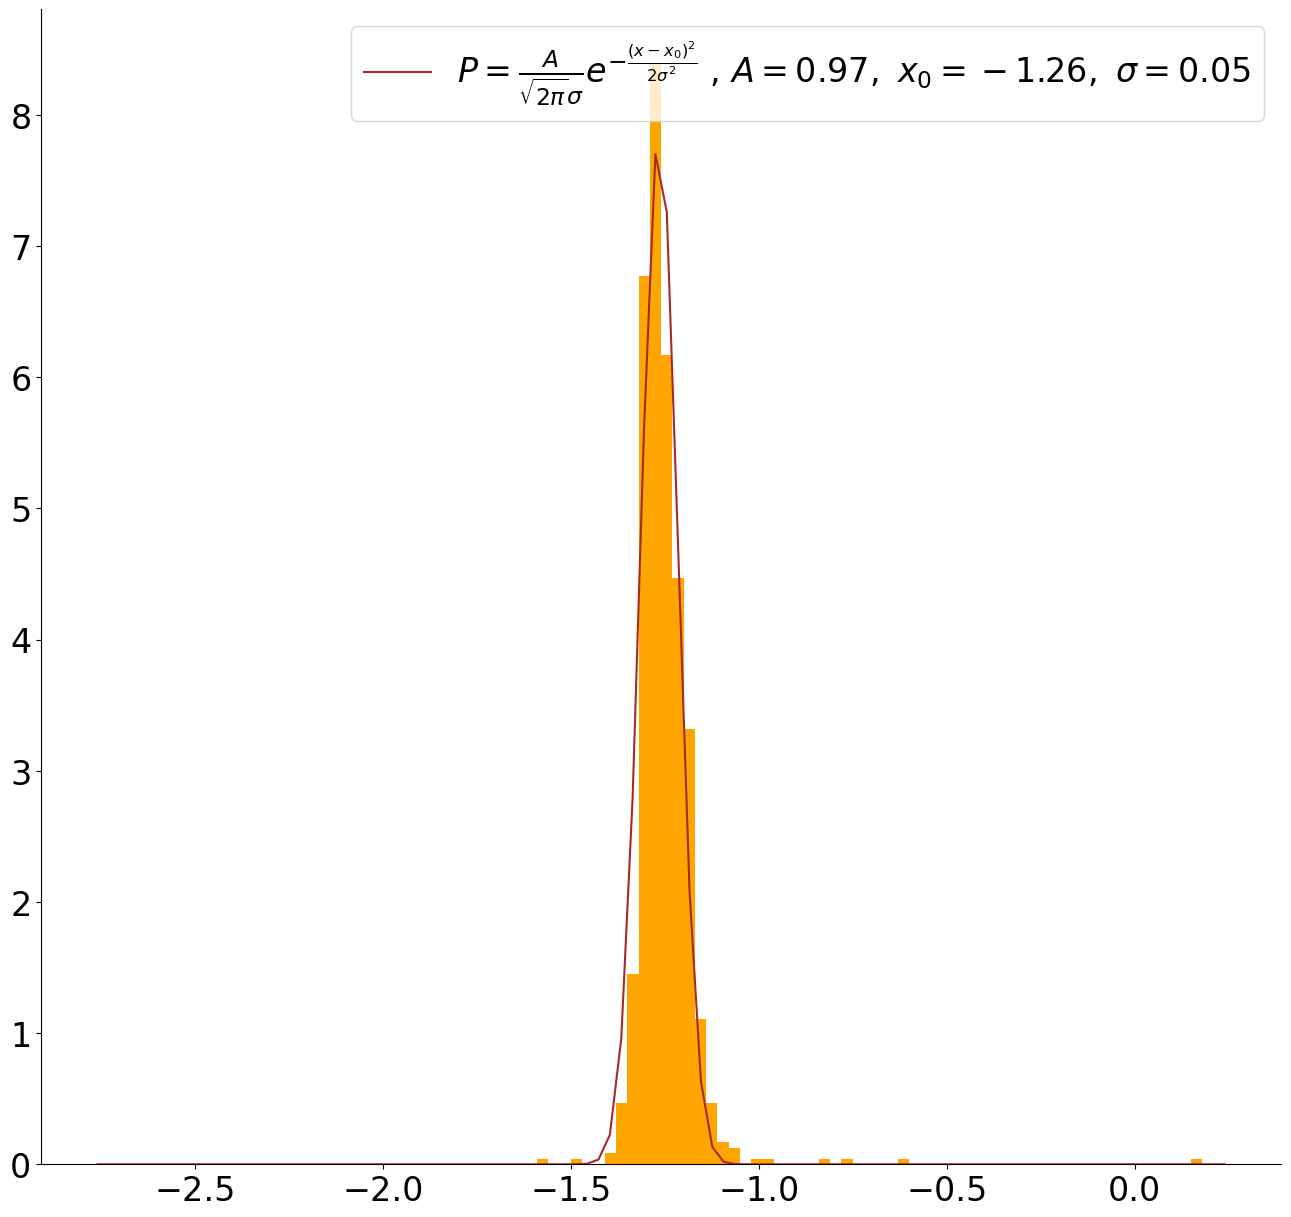

(array([ 0.97383476, -1.2647543 ,  0.04933179]),
 array([[ 7.14082722e-04,  8.73704720e-14,  2.41155243e-05],
        [ 8.73704720e-14,  2.44324005e-06, -4.56040097e-13],
        [ 2.41155243e-05, -4.56040097e-13,  2.44324011e-06]]))

In [79]:
plot_gaussian1(theta_data_786[45*64+31],bins=100,plot_range=(-1.5-1.26,1.5-1.26),plot=True,initial_guess=[1, 0, 1], rm_nan=True,figsize=(16,15))

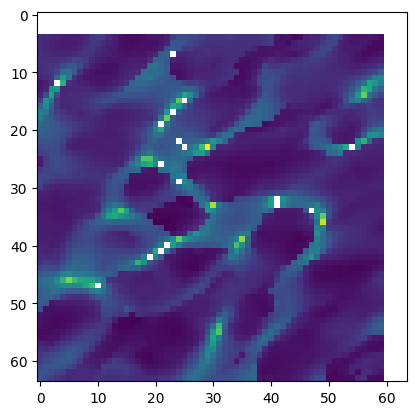

In [80]:
plt.imshow(std_786[2].reshape(64,64)/np.pi*180)

In [81]:
(np.sqrt(np.diag(theta_cor[0]+theta_cor[1]+theta_cor[2]+theta_cor[3]))/np.sqrt(std_786[0]**2+std_786[1]**2+std_786[2]**2+std_786[3]**2))[45*64+31]

np.float64(1.651416351737656)

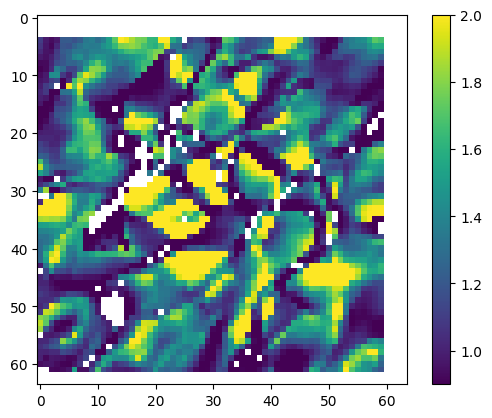

In [82]:
plt.imshow((np.sqrt(np.diag(theta_cor[0]+theta_cor[1]+theta_cor[2]+theta_cor[3]))/np.sqrt(std_786[0]**2+std_786[1]**2+std_786[2]**2+std_786[3]**2)).reshape(64,64))
plt.colorbar()
plt.clim(0.9,2)

In [83]:
np.std(theta_data_vonmises_list[num].reshape(1572,4096).T[45*64+31])

np.float64(0.398691961449752)

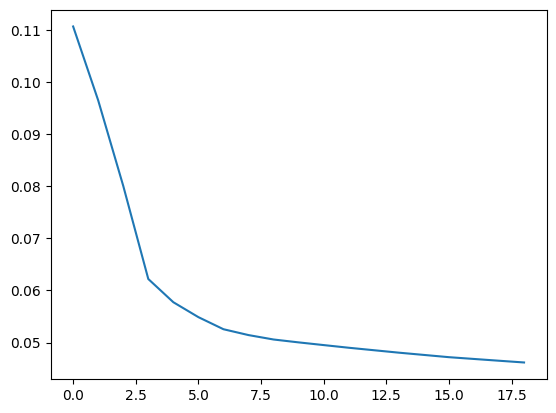

In [84]:
plt.plot([np.std(np.sort(theta_data_786[45*64+31])[de:-de]) for de in range(1,20)])

In [85]:
np.std(theta_data_786[45*64+31])

np.float64(0.1239376663120224)

In [86]:
def get_final_cut(mode="cor_grmhd"):
    # mode: "std", "cor", "cor_grmhd"
    # Delta_theta = [CircleCalc.circle_sub_evpa(theta_mean[1],theta_mean[0]).flatten(),CircleCalc.circle_sub_evpa(theta_mean[3],theta_mean[2]).flatten()] # evpasub
    Delta_theta = [CircleCalc.circle_sub_evpa(mean_786[1],mean_786[0]),CircleCalc.circle_sub_evpa(mean_786[3],mean_786[2])] # evpasub
    # Delta_theta = [np.zeros(resolution*resolution),np.zeros(resolution*resolution)]

    # Delta_std =[np.reshape(np.sqrt(theta_std[1]*theta_std[1]+theta_std[0]*theta_std[0]),4096),np.reshape(np.sqrt(theta_std[3]*theta_std[3]+theta_std[2]*theta_std[2]),4096)]
    Delta_std=[np.sqrt(std_786[1]*std_786[1]+std_786[0]*std_786[0]),np.sqrt(std_786[3]*std_786[3]+std_786[2]*std_786[2])]
    cor_std = np.asarray([(theta_cor[1]+theta_cor[0]),(theta_cor[3]+theta_cor[2])])
    # cor_std = [theta_cor[1],theta_cor[2]]
    # print(theta_cor[1][1550][1500])
    badset_with_large_delta=[] # deepcopy(badset)
    for i in range(resolution):
        for j in range(resolution):
            for l in range(4):
                # if theta_mean[l][i][j] == 0 and theta_std[l][i][j] == 0:
                if mean_786[l][i*resolution+j] == 0 and std_786[l][i*resolution+j] == 0 or np.isnan(mean_786[l][i*resolution+j]) or np.isnan(std_786[l][i*resolution+j]):
                    badset_with_large_delta.append(i*resolution+j)
            if condition2to9[i,j]:
                if np.isnan(diffs_axion_evpa_std[i,j]):
                    # pass
                    for lll in range(16):
                        diffs_axion_evpa_std_t[lll][i,j]=1/2/np.pi # caution
                    diffs_axion_evpa_std[i,j]=1/2/np.pi # caution
                    # badset_with_large_delta.append(i*resolution+j)
                    # if i <5.5 or j <1.5:
                    #     badset.append(i*resolution+j)
            else:
                badset_with_large_delta.append(i*resolution+j)
            # max_delta_theta=10
            # if Delta_theta[0][i*resolution+j]>max_delta_theta or Delta_theta[1][i*resolution+j]>max_delta_theta or Delta_theta[0][i*resolution+j]<-max_delta_theta or Delta_theta[1][i*resolution+j]<-max_delta_theta:
            #     badset_with_large_delta.append(i*resolution+j)
    if mode == "std":
        for i in range(4096):
            if np.isnan(Delta_std[0][i]) or np.isnan(Delta_std[1][i]):
                badset_with_large_delta.append(i)

    badset_with_large_delta=list(set(badset_with_large_delta))
    print(len(badset_with_large_delta))

    g_res = 40
    final_cut = [0 for omega in range(10,45)]
    temp_sig = []
    for omega in range(10,45):
        tbadset = deepcopy(badset_with_large_delta)
        goodset = list(range(resolution*resolution))
        c = 0.005

        if omega>40:
            pass
        omega = omega*0.01
        print(omega)
        Fit_result = np.load(f'GRMHD/data/different_omega/{omega}/EVPA_result.npy')
        for x in range(len(xy_coord)):
            i = int(np.floor(x/64))
            j = x%64

            #* Change P_mean< : 0E9: full image.    0.1E9: 600 pixels.    0.5E9:    150 pixels.            0.9E9: 50 pixels. 
            # dynamic_cut = 0.15*np.max(I_mean)
            dynamic_cut=0.1E9
            if P_mean[1][i][j] <dynamic_cut:
                tbadset.append(x)
            # if (i-32)*(i-32)+(j-32)*(j-32)>16*16:
            #     tbadset.append(x)
            if Fit_result[i][j][0] == -3 and Fit_result[i][j][1] ==-3:
                tbadset.append(x)
        tbadset = np.unique(tbadset)
        tbadset.sort()
        for x in range(len(tbadset)):
            goodset.remove(tbadset[x])
        goodsetrow = np.asarray([[x for y in goodset] for x in goodset])
        goodsetcol = np.asarray([goodset for x in goodset])
        # print(np.mean([((Fit_result[:,:,0])[x//64][x%64]/theta_std[0][x//64][x%64])**2 for x in goodset]))
        phi_0  = np.linspace(0,2*np.pi,16)
        gagg = np.logspace(np.log10(1/137.),2,g_res)
        prgagg = np.zeros(g_res)
        Delta_theta_theory = [[np.zeros((resolution,resolution)),np.zeros((resolution,resolution))] for i in range(16)]
        llh_axion = np.zeros((g_res,16))
        llh_axion_g = np.zeros(g_res)
        llh_astro = np.zeros((g_res,16))
        llh_astro_g = np.zeros(16)
        print(np.shape(np.asarray(cor_std[0][goodsetrow,goodsetcol])))
        # M_all=[np.asarray(cor_std)+cor_grmhd+np.diag(np.power(np.reshape(diffs_axion_evpa_std_t[i],4096),2)) for i in range(16) ]
        # M_inv = [[get_inv(np.asarray(M_all[i][0][goodsetrow,goodsetcol])),get_inv(np.asarray(M_all[i][0][goodsetrow,goodsetcol]))] for i in range(16)]
        # np.save(f'M_inv_{omega}',M_inv)
        # np.save(f'cor_std',cor_std)
        # print(f"{np.max(M_inv)},{np.min(M_inv)}")
        # print(f"{np.max(np.asarray(M_all[i][0][goodsetrow,goodsetcol]))},{np.min(np.asarray(M_all[i][0][goodsetrow,goodsetcol]))}")

        amp = np.asarray(Fit_result[:,:,0])
        print(amp.mean(),amp.max())
        ini_phase = np.asarray(Fit_result[:,:,1])
        offset = np.asarray(Fit_result[:,:,2]) # /180*np.pi
        
        if mode == "std":
            cor_std_good=np.asarray([np.diag(Delta_std[0])**2,np.diag(Delta_std[1])**2])[:,goodsetrow,goodsetcol]
        else:
            cor_std_good=cor_std[:,goodsetrow,goodsetcol]
        if mode == "cor_grmhd":
            cor_grmhd_good=cor_grmhd[goodsetrow,goodsetcol]
            tmpCorAxion=[np.diag(np.power(np.reshape(diffs_axion_evpa_std_t[i],4096),2))[goodsetrow,goodsetcol]*(f_axion_norm(omega,R_photon_ring)/f_axion_norm(0.4,R_photon_ring))**2 for i in range(16)]
        else:
            cor_grmhd_good=0
            tmpCorAxion=[0 for i in range(16)]
        for g in range(g_res):
            # print(g)
            M_all=[cor_std_good+cor_grmhd_good+tmpCorAxion[i]*(gagg[g])**2 for i in range(16) ]
            # M_inv = [[get_inv(M_all[i][0])]*2 for i in range(16)]

            for l in range(16):

                
                
                Delta_theta_theory[l][0] = 2*amp*np.sin(0.112411*omega/2*24)*np.sin(0.112411*omega/2*6)/(0.112411*omega/2*6)*np.sin(phi_0[l]+ini_phase)/0.5*gagg[g] #?
                Delta_theta_theory[l][1] = 2*amp*np.sin(0.112411*omega/2*24)*np.sin(0.112411*omega/2*6)/(0.112411*omega/2*6)*np.sin(phi_0[l]+0.112411*omega/2*24*5+ini_phase)/0.5*gagg[g]

                Delta_theta_theory[l][0] = np.reshape(Delta_theta_theory[l][0],4096)
                Delta_theta_theory[l][1] = np.reshape(Delta_theta_theory[l][1],4096)


                for k in range(2):
                    x_diff = np.matrix((Delta_theta_theory[l][k]*5-Delta_theta[k]*0)[goodset])

                    #* Calculate with cor_std.
                    # llh_axion[g][l] +=np.exp(-(np.array(np.dot(x_diff,np.dot(M_inv[l][k],x_diff.T)))[0][0])/2.)
                    llh_axion[g][l] +=np.exp(-fastxtMinvx(np.asarray(x_diff)[0],M_all[l][k])/2.)
                    # llh_axion[g][l] +=np.exp(0)
                    
                    #* Calculate with std.
                    # llh_axion[g][l] +=np.exp(-np.sum(x_diff*x_diff.T/(2*Delta_std[k][goodset]*Delta_std[k][goodset])))

            llh_axion_g = np.sum(llh_axion,axis=1)/16
            # llh_astro_g = np.sum(llh_astro,axis=1)/160
            for x in range(g_res):
                if x>=g:
                    prgagg[x] += llh_axion_g[g]/g_res
        g=0
        while prgagg[g]<prgagg[g_res-1]*0.95:
            g+=1
        g-=1
        # print(prgagg[-2])
        final_cut[round((omega-0.1)/0.01)] = (prgagg[g_res-1]*0.95-prgagg[g])/(prgagg[g+1]-prgagg[g])*(np.log10(gagg[g+1])-np.log10(gagg[g]))+np.log10(gagg[g])
        print(f'{round((omega-0.1)/0.01)} is done!')
    
    plt.plot([omega*0.01 for omega in range(10,45)],final_cut,'s-')
    name = mode
    plt.savefig(f'Results/figure/{name}.pdf')
    plotting_script([omega*0.01 for omega in range(10,45)],final_cut,name)
    np.savez(f'Results/data/{name}',omegas = [omega*0.01 for omega in range(10,45)],cuts = final_cut)
    return final_cut

3241
0.1
(540, 540)
0.0014981062270165422 0.004769736328783366
0 is done!
0.11
(540, 540)
0.0017380764397918738 0.00562915915126139
1 is done!
0.12
(540, 540)
0.001989219365530126 0.00650955121197444
2 is done!
0.13
(540, 540)
0.0022525604589400203 0.007391635365240134
3 is done!
0.14
(540, 540)
0.002531826454408145 0.00826102741926068
4 is done!
0.15
(540, 540)
0.00282425442958796 0.009077855556346695
5 is done!
0.16
(540, 540)
0.003126091832086294 0.009799463396045307
6 is done!
0.17
(540, 540)
0.0034327347400857165 0.010377386558797483
7 is done!
0.18
(540, 540)
0.003753171236639048 0.01081195154707917
8 is done!
0.19
(540, 540)
0.004079850222465271 0.011060769797075312
9 is done!
0.2
(540, 540)
0.004396868671631508 0.011136752374615283
10 is done!
0.21
(540, 540)
0.004708562935053972 0.011932717994610285
11 is done!
0.22
(540, 540)
0.0049988736671895285 0.012646475271685853
12 is done!
0.23
(540, 540)
0.005288706110669394 0.013346436785094893
13 is done!
0.24
(540, 540)
0.005604370

<Figure size 640x480 with 0 Axes>

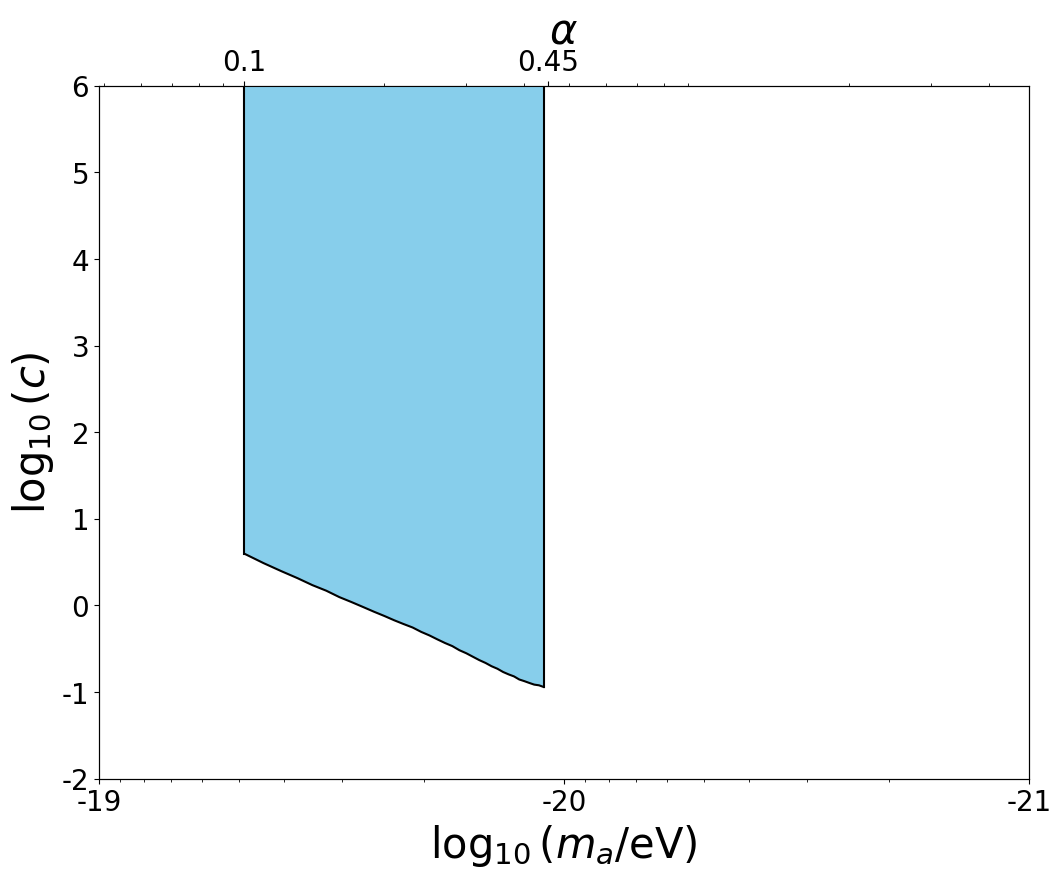

In [87]:
final_cut=get_final_cut(mode="std")

In [88]:
final_cut=get_final_cut(mode="cor")

3241
0.1
(540, 540)
0.0014981062270165422 0.004769736328783366
0 is done!
0.11
(540, 540)
0.0017380764397918738 0.00562915915126139
1 is done!
0.12
(540, 540)
0.001989219365530126 0.00650955121197444
2 is done!
0.13
(540, 540)
0.0022525604589400203 0.007391635365240134


KeyboardInterrupt: 

0.1
(540, 540)
0.0014981062270165422 0.004769736328783366
0 is done!
0.11
(540, 540)
0.0017380764397918738 0.00562915915126139
1 is done!
0.12
(540, 540)
0.001989219365530126 0.00650955121197444
2 is done!
0.13
(540, 540)
0.0022525604589400203 0.007391635365240134
3 is done!
0.14
(540, 540)
0.002531826454408145 0.00826102741926068
4 is done!
0.15
(540, 540)
0.00282425442958796 0.009077855556346695
5 is done!
0.16
(540, 540)
0.003126091832086294 0.009799463396045307
6 is done!
0.17
(540, 540)
0.0034327347400857165 0.010377386558797483
7 is done!
0.18
(540, 540)
0.003753171236639048 0.01081195154707917
8 is done!
0.19
(540, 540)
0.004079850222465271 0.011060769797075312
9 is done!
0.2
(540, 540)
0.004396868671631508 0.011136752374615283
10 is done!
0.21
(540, 540)
0.004708562935053972 0.011932717994610285
11 is done!
0.22
(540, 540)
0.0049988736671895285 0.012646475271685853
12 is done!
0.23
(540, 540)
0.005288706110669394 0.013346436785094893
13 is done!
0.24
(540, 540)
0.00560437032396

<Figure size 640x480 with 0 Axes>

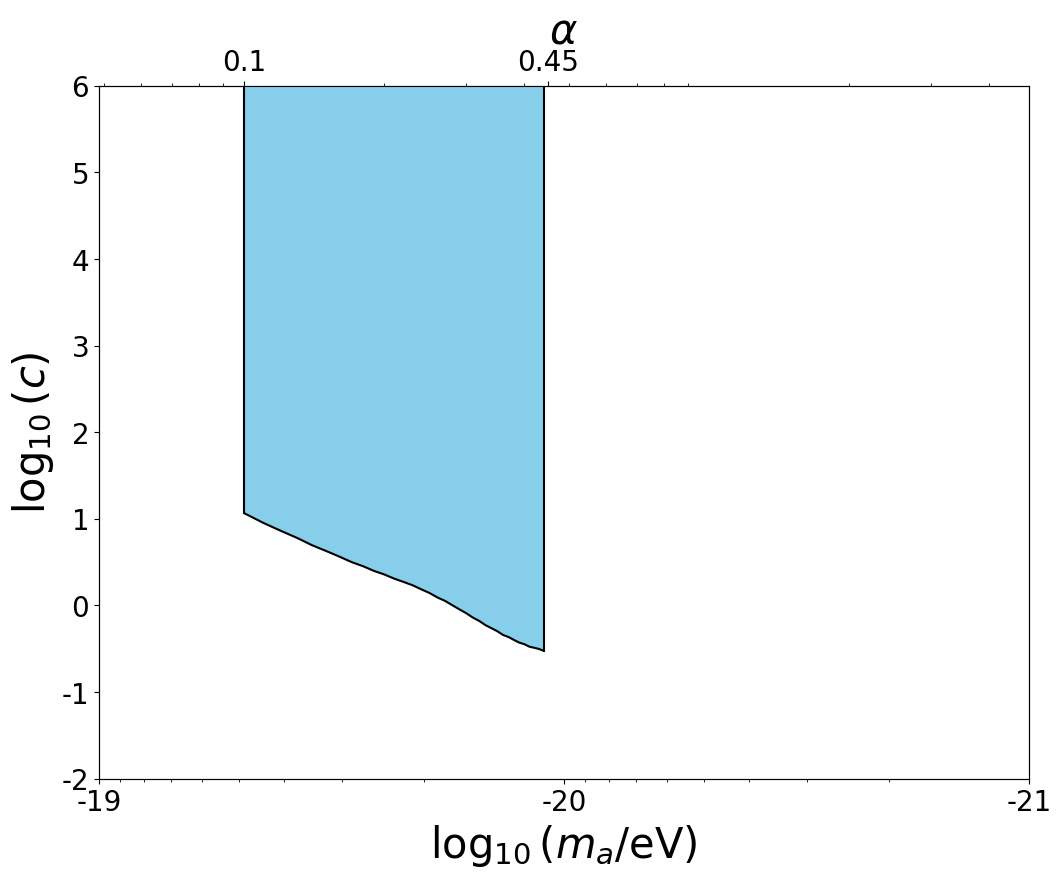

In [ ]:
final_cut=get_final_cut(mode="cor_grmhd")

# 1d

In [102]:
import pickle
import numpy as np
import matplotlib
import os
import argparse
import numpy as np
from copy import deepcopy

from scipy.interpolate import griddata, interp2d
from scipy import integrate, optimize
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter


def plotting_script(xarray,yarray,name):
    plt.clf()
    fig,ax = plt.subplots(figsize=(12,9))
    ax.set_xscale('log')
    ax2 = ax.twiny()
    ax2.set_xscale('log')
    ax2.set_ylim(-2,6)
    ax.set_yticks([-2,-1,0,1,2,3,4,5,6])
    ax.set_yticklabels(['-2','-1','0','1','2','3','4','5','6'],size=20)
    ax.set_ylabel('$\log_{10}(c)$',size=30)
    ax2.set_xticks([0.1,0.45])
    ax2.set_xticklabels(['0.1','0.45'],size=20)
    ax2.set_xlabel(r'$ \alpha $',size=30)
    ax2.set_xlim(0.0486495,4.86495)
    ax.set_xlim(1E-19, 1E-21)
    ax.set_xticks([1E-21,1E-20,1E-19])
    ax.set_xticklabels(['-21','-20','-19'],size=20)
    ax.set_xlabel('$\log_{10}(m_a/\mathrm{eV})$',size=30)
    ax2.plot(xarray,yarray,'black')
    ax2.plot([np.max(xarray),np.max(xarray)],[yarray[-1],6],'black')
    ax2.plot([np.min(xarray),np.min(xarray)],[yarray[0],6],'black')

    xcolor = ['SkyBlue','#C8C8A9','#FE4365']
    ax2.fill_between(xarray,yarray, 6,ls='-',lw=2,fc = xcolor[0],alpha=1)
    plt.savefig(f'new_static/{name}.pdf',dpi=600)


theta_mean = []
theta_std =[]
theta_cor = []
badset = []
resolution = 360

num=0
for day in [95,96,100,101]:
    # with np.load(f'./EHT-Imaging/{day}_1d.npz') as data:
    #     theta_mean.append(data['arr_0'])
    #     theta_std.append(data['arr_1'])
    
    theta_data=np.load(f'./EHT-Imaging/{day}_EVPA_1d.npy')
    # _tmp_sub = CircleCalc.circle_sub_evpa(theta_data,theta_mean[num])
    # # cor_data = np.dot(_tmp_sub.T,_tmp_sub)/_tmp_sub.shape[0]
    # cor_data = np.dot(_tmp_sub[np.argsort(sum_of_pixels)[:786],:].T,_tmp_sub[np.argsort(sum_of_pixels)[:786],:])/_tmp_sub.shape[0]
    # theta_cor.append(cor_data)
    theta_data_1d_786=theta_data[np.argsort(sum_of_pixels)[:786]]
    theta_data_1d_786_vonmises_mean=np.apply_along_axis(vonmises_mean,0,theta_data_1d_786)
    theta_data_1d_786=CircleCalc.circle_sub_evpa(theta_data_1d_786,theta_data_1d_786_vonmises_mean)+theta_data_1d_786_vonmises_mean
    tmpres=np.apply_along_axis(fit_gaussian2,0,theta_data_1d_786)
    theta_mean.append(tmpres[0])
    theta_std.append(tmpres[1])
    cor_data=CircleCalc.circle_sub_evpa(theta_data_1d_786,tmpres[0]).T
    theta_cor.append(np.dot(cor_data,cor_data.T)/786)
    num+=1

xy_coord = [i for i in range(resolution)]
Delta_theta = [theta_mean[1]-theta_mean[0],theta_mean[3]-theta_mean[2]]
# Delta_theta = [np.zeros(resolution),np.zeros(resolution)]
Delta_std =[np.sqrt(theta_std[1]*theta_std[1]+theta_std[0]*theta_std[0]),np.sqrt(theta_std[3]*theta_std[3]+theta_std[2]*theta_std[2])]
cor_std = np.asarray([theta_cor[1]+theta_cor[0],theta_cor[3]+theta_cor[2]])
# cor_std = [theta_cor[0],theta_cor[2]]
for i in range(resolution):
    if np.isnan(diffs_axion_evpa_std_1d[i]):
        badset.append(i)
    for l in range(4):
        if theta_mean[l][i] == 0 and theta_std[l][i] == 0 or np.isnan(theta_mean[l][i]) or np.isnan(theta_std[l][i]):
            badset.append(i)
badset=list(set(badset))

<>:24: SyntaxWarning: invalid escape sequence '\l'
<>:32: SyntaxWarning: invalid escape sequence '\l'
<>:24: SyntaxWarning: invalid escape sequence '\l'
<>:32: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_681590/186697978.py:24: SyntaxWarning: invalid escape sequence '\l'
  ax.set_ylabel('$\log_{10}(c)$',size=30)
/tmp/ipykernel_681590/186697978.py:32: SyntaxWarning: invalid escape sequence '\l'
  ax.set_xlabel('$\log_{10}(m_a/\mathrm{eV})$',size=30)


badfit
badfit


/tmp/ipykernel_681590/2155927868.py:6: OptimizeWarning: Covariance of the parameters could not be estimated
  popt,pcov = optimize.curve_fit(gaussian2,xarray,counts,p0=[vonmises_mean(d1evpaarr),1,786]) #,maxfev=50000,gtol=1e-10


badfit
badfit
badfit, error Optimal parameters not found: Number of calls to function has reached maxfev = 800.
badfit
badfit
badfit
badfit, error Optimal parameters not found: Number of calls to function has reached maxfev = 800.
badfit
badfit, error Optimal parameters not found: Number of calls to function has reached maxfev = 800.
badfit, error Optimal parameters not found: Number of calls to function has reached maxfev = 800.
badfit
badfit
badfit
badfit
badfit
badfit, error Optimal parameters not found: Number of calls to function has reached maxfev = 800.
badfit, error Optimal parameters not found: Number of calls to function has reached maxfev = 800.
badfit, error Optimal parameters not found: Number of calls to function has reached maxfev = 800.
badfit, error Optimal parameters not found: Number of calls to function has reached maxfev = 800.
badfit, error Optimal parameters not found: Number of calls to function has reached maxfev = 800.
badfit, error Optimal parameters not foun

KeyboardInterrupt: 

In [ ]:
def get_final_cut_1d(mode="cor_grmhd"):
    g_res = 40
    final_cut = [0 for omega in range(10,45)]
    for omega in range(10,45):
        tbadset = deepcopy(badset)
        goodset = list(range(resolution))
        c = 0.005
        omega = omega*0.01
        Fit_result = np.load(f'GRMHD/data/different_omega/{omega}/EVPA_phi_10deg_result.npy')
        for i in range(resolution):
            if np.round(i%10) != 3:  # point最多
                tbadset.append(i)
            if Fit_result[i][0] == -3 and Fit_result[i][1] ==-3:
                tbadset.append(i)
        tbadset = np.unique(tbadset)
        tbadset.sort()
        for x in range(len(tbadset)):
            goodset.remove(tbadset[x])
        goodsetrow = np.asarray([[x for y in goodset] for x in goodset])
        goodsetcol = np.asarray([goodset for x in goodset])
        phi_0  = np.linspace(0,2*np.pi,16)
        gagg = np.logspace(np.log10(1/137.),2,g_res)
        prgagg = np.zeros(g_res)
        Delta_theta_theory = [[np.zeros(resolution),np.zeros(resolution)] for i in range(16)]
        llh_axion = np.zeros((g_res,16))
        llh_axion_g = np.zeros(g_res)
        llh_astro = np.zeros((g_res,16))
        llh_astro_g = np.zeros(16)
        print(np.shape(np.asarray(cor_std[0][goodsetrow,goodsetcol])))
        # M_inv = [get_inv(np.asarray(cor_std[0][goodsetrow,goodsetcol])),get_inv(np.asarray(cor_std[1][goodsetrow,goodsetcol]))]
        # np.save(f'M_inv_{omega}_1d',M_inv)
        # np.save(f'cor_std_1d',cor_std)


        if mode == "std":
            cor_std_good=np.asarray([np.diag(Delta_std[0])**2,np.diag(Delta_std[1])**2])[:,goodsetrow,goodsetcol]
        else:
            cor_std_good=cor_std[:,goodsetrow,goodsetcol]
        print(np.sort(np.sqrt(np.diag(cor_std_good[0])))/np.pi*180)
        print(np.sort(np.sqrt(np.diag(cor_std_good[1])))/np.pi*180)
        if mode == "cor_grmhd":
            cor_grmhd_good=cor_grmhd[goodsetrow,goodsetcol] # 虽然这里的grmhd是4096x4096的矩阵，但反正取的是360x360内所以无所谓
            tmpCorAxion=[np.diag(np.power(diffs_axion_evpa_std_t_1d[i],2))[goodsetrow,goodsetcol]*(f_axion_norm(omega,R_photon_ring)/f_axion_norm(0.4,R_photon_ring))**2 for i in range(16)]
        else:
            cor_grmhd_good=0
            tmpCorAxion=[0 for i in range(16)]
        for g in range(g_res):
            M_all=[cor_std_good+cor_grmhd_good+tmpCorAxion[i]*(gagg[g])**2 for i in range(16) ]
            for l in range(16):
                amp = np.asarray(Fit_result[:,0])
                ini_phase = np.asarray(Fit_result[:,1])
                offset = np.asarray(Fit_result[:,2])
                
                Delta_theta_theory[l][0] = 2*amp*np.sin(0.112411*omega/2*24)*np.sin(0.112411*omega/2*6)/(0.112411*omega/2*6)*np.sin(phi_0[l]+ini_phase)/0.5*gagg[g]
                Delta_theta_theory[l][1] = 2*amp*np.sin(0.112411*omega/2*24)*np.sin(0.112411*omega/2*6)/(0.112411*omega/2*6)*np.sin(phi_0[l]+0.112411*omega/2*24*5+ini_phase)/0.5*gagg[g]

                # Delta_theta_theory[l][0] = np.reshape(Delta_theta_theory[l][0],4096)
                # Delta_theta_theory[l][1] = np.reshape(Delta_theta_theory[l][1],4096)   


                for k in range(2):
                    x_diff = np.matrix((Delta_theta_theory[l][k]*5-Delta_theta[k]*0)[goodset])
                    #* Calculate with cor_std.
                    # llh_axion[g][l] +=np.exp(-(np.array(np.dot(x_diff,np.dot(M_inv[k],x_diff.T)))[0][0])/2.)
                    llh_axion[g][l] +=np.exp(-fastxtMinvx(np.asarray(x_diff)[0],M_all[l][k])/2.)
                    
                    #* Calculate with std.
                    # llh_axion[g][l] +=np.exp(-np.sum(x_diff*x_diff.T/(2*Delta_std[k][goodset]*Delta_std[k][goodset])))

            llh_axion_g = np.sum(llh_axion,axis=1)/16
            # llh_astro_g = np.sum(llh_astro,axis=1)/160
            for x in range(g_res):
                if x>=g:
                    prgagg[x] += llh_axion_g[g]/g_res
        g=0
        while prgagg[g]<prgagg[g_res-1]*0.95:
            g+=1
        g-=1
        final_cut[round((omega-0.1)/0.01)] = (prgagg[g_res-1]*0.95-prgagg[g])/(prgagg[g+1]-prgagg[g])*(np.log10(gagg[g+1])-np.log10(gagg[g]))+np.log10(gagg[g])
        print(f'{round((omega-0.1)/0.01)} is done!')
    plt.plot([omega*0.01 for omega in range(10,45)],final_cut,'s-')
    name = mode
    plt.savefig(f'Results/figure/{name}_1d.pdf')
    plotting_script([omega*0.01 for omega in range(10,45)],final_cut,name)
    np.savez(f'Results/data/{name}_1d',omegas = [omega*0.01 for omega in range(10,45)],cuts = final_cut)
    return final_cut


(27, 27)
[ 4.67707069  6.29323105  6.78638548  7.77369645  8.55245694  8.92637298
  9.62282234 10.69509863 10.71967304 11.47974703 11.62288329 11.76471392
 12.8494864  12.8856328  15.0512521  15.89735579 16.05189316 17.9903991
 17.99643544 19.22295496 25.39574371 33.45899205 39.10459073 40.69926796
 50.38342146 54.76829177 70.0334302 ]
[ 4.7865837   6.79626142  6.90127791  7.77971802  9.48430832 11.0724398
 13.75907005 14.76872053 15.14417931 15.27967986 15.61868643 17.38792301
 17.43282318 21.00095494 23.42830151 24.15678242 24.64515001 29.5288076
 30.71036505 32.25778689 38.41673919 38.48912677 50.42450893 51.25503592
 56.7987292  70.99250633 86.28378906]
0 is done!
(27, 27)
[ 4.67707069  6.29323105  6.78638548  7.77369645  8.55245694  8.92637298
  9.62282234 10.69509863 10.71967304 11.47974703 11.62288329 11.76471392
 12.8494864  12.8856328  15.0512521  15.89735579 16.05189316 17.9903991
 17.99643544 19.22295496 25.39574371 33.45899205 39.10459073 40.69926796
 50.38342146 54.7682917

[np.float64(1.2403087869761016),
 np.float64(1.1352471687384127),
 np.float64(1.0330952626491043),
 np.float64(0.9517882840553665),
 np.float64(0.8695271850922962),
 np.float64(0.7942035448733521),
 np.float64(0.7193573172700491),
 np.float64(0.6539686319345982),
 np.float64(0.5938473722386215),
 np.float64(0.5332980869702255),
 np.float64(0.4788100550438412),
 np.float64(0.42013764655077),
 np.float64(0.37839124246779865),
 np.float64(0.33281662110483484),
 np.float64(0.2801796435905778),
 np.float64(0.24068607548156878),
 np.float64(0.19069581672096036),
 np.float64(0.16078143128175257),
 np.float64(0.1247999865563923),
 np.float64(0.07659438339776647),
 np.float64(0.05459888072604195),
 np.float64(0.010656850793503769),
 np.float64(-0.024220019934197437),
 np.float64(-0.04520709296849808),
 np.float64(-0.09067584479807592),
 np.float64(-0.11367353087295398),
 np.float64(-0.14851055795192697),
 np.float64(-0.1823862073525225),
 np.float64(-0.19434521197392174),
 np.float64(-0.2400779

<Figure size 640x480 with 0 Axes>

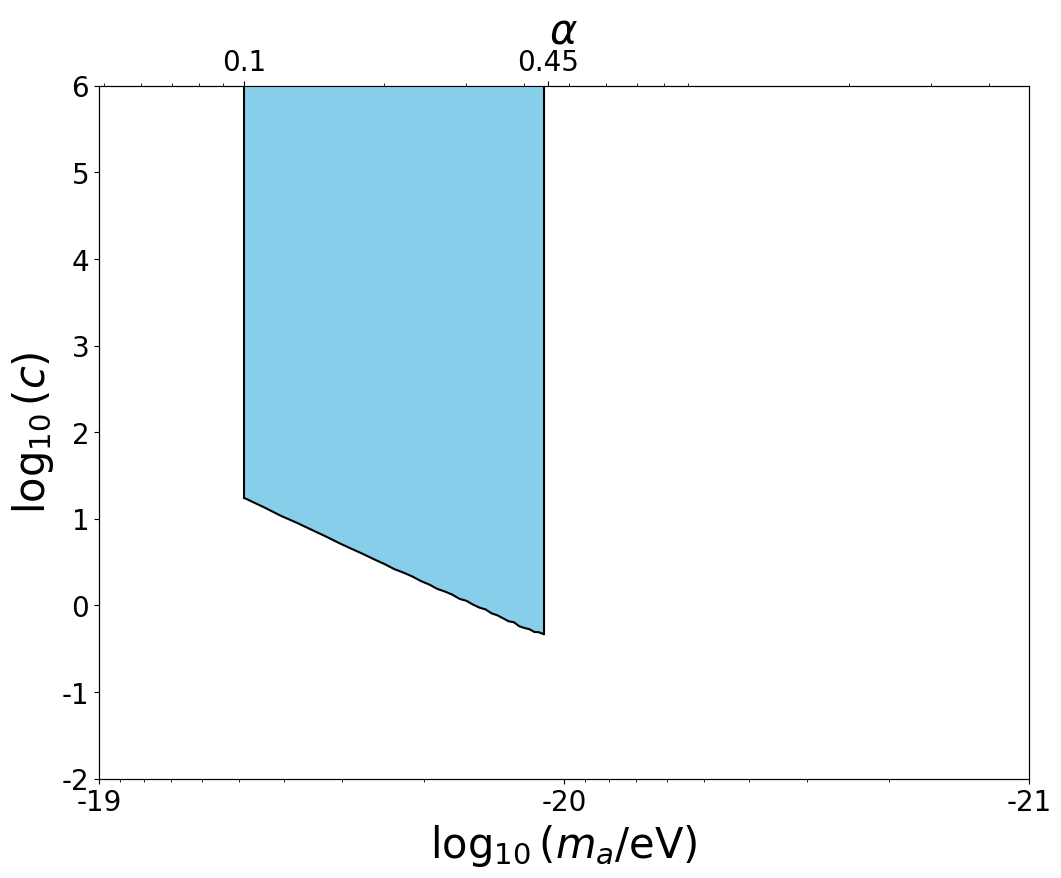

In [50]:
get_final_cut_1d(mode="std")

(27, 27)
[ 9.9502881   9.97951728 11.28501616 11.6371526  12.11459544 12.89496322
 13.14196929 15.03003174 15.36312105 15.46607233 16.76606153 17.57612779
 17.86231376 21.96384973 28.34078708 28.8487039  28.99893374 29.03256839
 34.02817148 37.31279907 38.58955229 41.8978292  41.94627861 47.67006147
 48.37117041 48.52036589 53.66436308]
[10.95054419 14.61955475 16.32110465 22.80070414 22.90004647 23.71443695
 25.57279646 25.85749789 29.94627788 33.89688266 34.99030661 35.1801448
 35.23826176 37.08801237 37.40294403 38.18324153 39.72428644 40.08746699
 40.26593274 41.63232311 43.31346967 44.53422008 44.7462181  44.91614491
 47.73215129 48.76496808 53.95570202]
0 is done!
(27, 27)
[ 9.9502881   9.97951728 11.28501616 11.6371526  12.11459544 12.89496322
 13.14196929 15.03003174 15.36312105 15.46607233 16.76606153 17.57612779
 17.86231376 21.96384973 28.34078708 28.8487039  28.99893374 29.03256839
 34.02817148 37.31279907 38.58955229 41.8978292  41.94627861 47.67006147
 48.37117041 48.5203

[np.float64(1.4862498074667148),
 np.float64(1.3911229120280202),
 np.float64(1.2881326043581),
 np.float64(1.2134088378967067),
 np.float64(1.122738879705287),
 np.float64(1.0456075028830274),
 np.float64(0.9812595518751833),
 np.float64(0.908032286508608),
 np.float64(0.8548701640588358),
 np.float64(0.7945175084403617),
 np.float64(0.7345584452092508),
 np.float64(0.6860551306981513),
 np.float64(0.6375806877075811),
 np.float64(0.5975151059221163),
 np.float64(0.5463158859139656),
 np.float64(0.4988623164666512),
 np.float64(0.4582000044795544),
 np.float64(0.41949102691749574),
 np.float64(0.3835527489764203),
 np.float64(0.3373251683246109),
 np.float64(0.3026687897763084),
 np.float64(0.2676707685549472),
 np.float64(0.23235408930179063),
 np.float64(0.2028375496872109),
 np.float64(0.16303077990036813),
 np.float64(0.1398666780379048),
 np.float64(0.10657654790036875),
 np.float64(0.07214975434227112),
 np.float64(0.05710132976800324),
 np.float64(0.02141193608580151),
 np.floa

<Figure size 640x480 with 0 Axes>

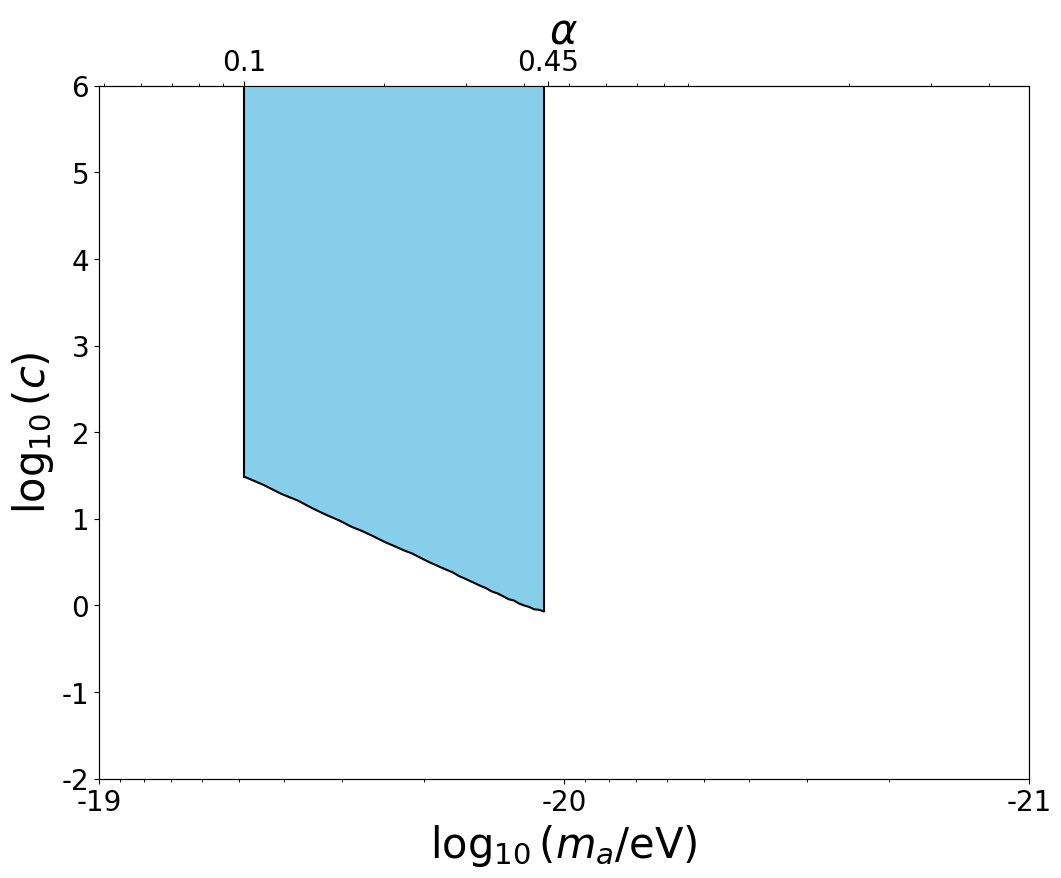

In [51]:
get_final_cut_1d(mode="cor")

(27, 27)
[ 9.9502881   9.97951728 11.28501616 11.6371526  12.11459544 12.89496322
 13.14196929 15.03003174 15.36312105 15.46607233 16.76606153 17.57612779
 17.86231376 21.96384973 28.34078708 28.8487039  28.99893374 29.03256839
 34.02817148 37.31279907 38.58955229 41.8978292  41.94627861 47.67006147
 48.37117041 48.52036589 53.66436308]
[10.95054419 14.61955475 16.32110465 22.80070414 22.90004647 23.71443695
 25.57279646 25.85749789 29.94627788 33.89688266 34.99030661 35.1801448
 35.23826176 37.08801237 37.40294403 38.18324153 39.72428644 40.08746699
 40.26593274 41.63232311 43.31346967 44.53422008 44.7462181  44.91614491
 47.73215129 48.76496808 53.95570202]
0 is done!
(27, 27)
[ 9.9502881   9.97951728 11.28501616 11.6371526  12.11459544 12.89496322
 13.14196929 15.03003174 15.36312105 15.46607233 16.76606153 17.57612779
 17.86231376 21.96384973 28.34078708 28.8487039  28.99893374 29.03256839
 34.02817148 37.31279907 38.58955229 41.8978292  41.94627861 47.67006147
 48.37117041 48.5203

[np.float64(1.5393492730252492),
 np.float64(1.4431215442132364),
 np.float64(1.3430523620870267),
 np.float64(1.2649964425199316),
 np.float64(1.1717341394279273),
 np.float64(1.098824775295876),
 np.float64(1.0262185131481107),
 np.float64(0.9513403234550503),
 np.float64(0.8994124531008625),
 np.float64(0.8322090168613837),
 np.float64(0.7788609957173993),
 np.float64(0.7234850995545005),
 np.float64(0.6767437076290918),
 np.float64(0.6355356037859141),
 np.float64(0.5829984001855352),
 np.float64(0.5370465531128403),
 np.float64(0.49323906122451994),
 np.float64(0.4558741833543454),
 np.float64(0.4182647381260509),
 np.float64(0.3715893597492251),
 np.float64(0.34025733575568123),
 np.float64(0.29874443136961926),
 np.float64(0.2649029882533153),
 np.float64(0.23855882167047848),
 np.float64(0.19172921836269763),
 np.float64(0.17044826845957056),
 np.float64(0.1385314940789525),
 np.float64(0.1004678683645722),
 np.float64(0.08493713651973098),
 np.float64(0.049380775066453206),
 n

<Figure size 640x480 with 0 Axes>

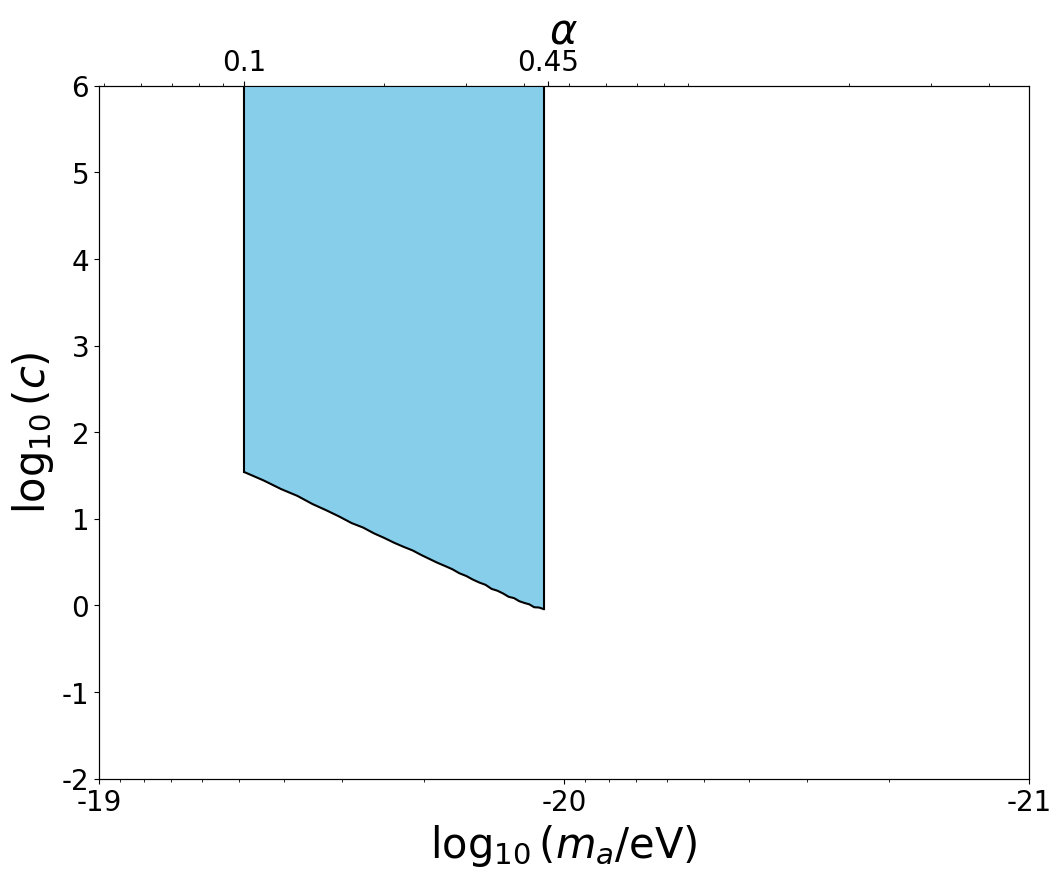

In [52]:
get_final_cut_1d(mode="cor_grmhd")

In [221]:
np.sqrt(np.diag(cor_std_good[0]))/np.pi*180

array([11.7563888 , 13.45154066, 26.38031961, 31.96265062, 21.22161131,
       18.93035074, 24.15504967, 26.65206932, 34.72027064, 19.61024197,
       14.58457443, 22.79992831, 20.15230603, 10.83766744, 10.34497303,
       11.43059054,  8.3288432 ])

In [217]:
np.sqrt(np.diag(cor_std_good[0]))/np.pi*180

array([11.43107396, 15.33082919, 29.91254594, 29.67396822, 24.92765656,
       19.30193136, 19.63667278, 25.56671903, 30.88545625, 34.37667603,
       23.72729762, 17.86171389, 15.92704258, 24.62061043,  7.95199034,
        9.91025657, 11.0482334 ,  9.84320908,  8.95129117, 10.55465118,
        7.60775649,  9.84547076])

In [220]:
final_cut

[np.float64(1.5312097620530989),
 np.float64(1.4369922722548818),
 np.float64(1.3398664207182276),
 np.float64(1.2533050079370815),
 np.float64(1.1680689398041517),
 np.float64(1.0922639381054249),
 np.float64(1.0208087835671018),
 np.float64(0.9512602095596117),
 np.float64(0.892502354155284),
 np.float64(0.8299052205634789),
 np.float64(0.7771637013990488),
 np.float64(0.723444582924998),
 np.float64(0.6786603392143057),
 np.float64(0.6328808033549145),
 np.float64(0.5861357086259048),
 np.float64(0.5412614126708223),
 np.float64(0.4991554791986416),
 np.float64(0.46258612307255254),
 np.float64(0.4236982486003438),
 np.float64(0.38387965961361864),
 np.float64(0.3515133215340765),
 np.float64(0.31349569413989065),
 np.float64(0.28013621230374697),
 np.float64(0.25094397114453676),
 np.float64(0.2136732520256614),
 np.float64(0.18553802007646877),
 np.float64(0.15671673509633913),
 np.float64(0.12592751148642095),
 np.float64(0.10187890903131192),
 np.float64(0.07255590864652472),
 n

In [207]:
final_cut

[np.float64(1.5028934084145136),
 np.float64(1.3939294101656103),
 np.float64(1.2984880164334047),
 np.float64(1.219521044625946),
 np.float64(1.1228947218706897),
 np.float64(1.0545351709889288),
 np.float64(0.9830719027876236),
 np.float64(0.9113186129136752),
 np.float64(0.8586672714176375),
 np.float64(0.7920957763987064),
 np.float64(0.7399947843873623),
 np.float64(0.6892863898285836),
 np.float64(0.6364081696191491),
 np.float64(0.5964752515228422),
 np.float64(0.5433239255800661),
 np.float64(0.4976455755368914),
 np.float64(0.4546506037196992),
 np.float64(0.40851450500056574),
 np.float64(0.37482212559147965),
 np.float64(0.3284562287731632),
 np.float64(0.2921153171488353),
 np.float64(0.2554134588560792),
 np.float64(0.21612976050799518),
 np.float64(0.1850722515333471),
 np.float64(0.1482043316761318),
 np.float64(0.11782979958308852),
 np.float64(0.08324602656325561),
 np.float64(0.05424944300450993),
 np.float64(0.030452466188061765),
 np.float64(-0.0037480913606893432),

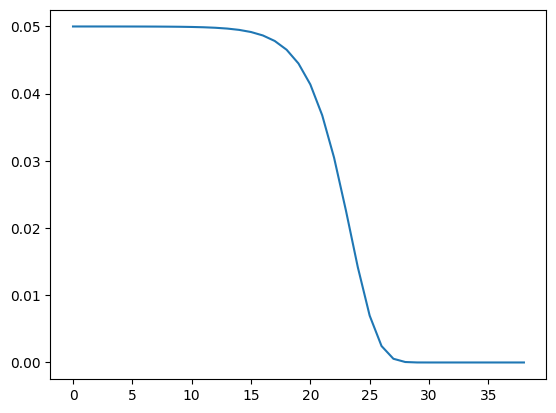

In [231]:
plt.plot(np.diff(prgagg))

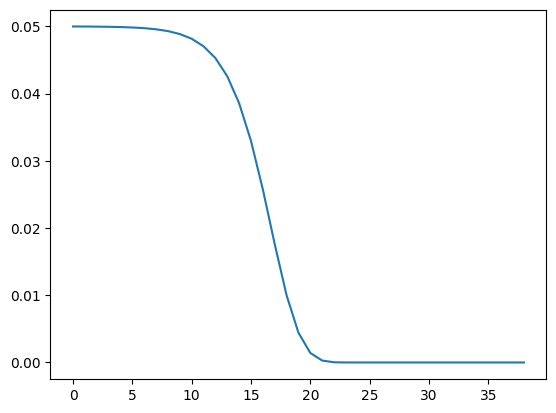

In [228]:
plt.plot(np.diff(prgagg))

In [169]:
final_cut1=np.load('M_all/new_static/l_cor_dyn_obs.npz')
final_cut2 = np.load('new_static/l_cor_1d.npz')

<>:9: SyntaxWarning: invalid escape sequence '\l'
<>:17: SyntaxWarning: invalid escape sequence '\l'
<>:9: SyntaxWarning: invalid escape sequence '\l'
<>:17: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_497813/3991053186.py:9: SyntaxWarning: invalid escape sequence '\l'
  ax.set_ylabel('$\log_{10}(c)$',size=30)
/tmp/ipykernel_497813/3991053186.py:17: SyntaxWarning: invalid escape sequence '\l'
  ax.set_xlabel('$\log_{10}(m_a/\mathrm{eV})$',size=30)


<Figure size 640x480 with 0 Axes>

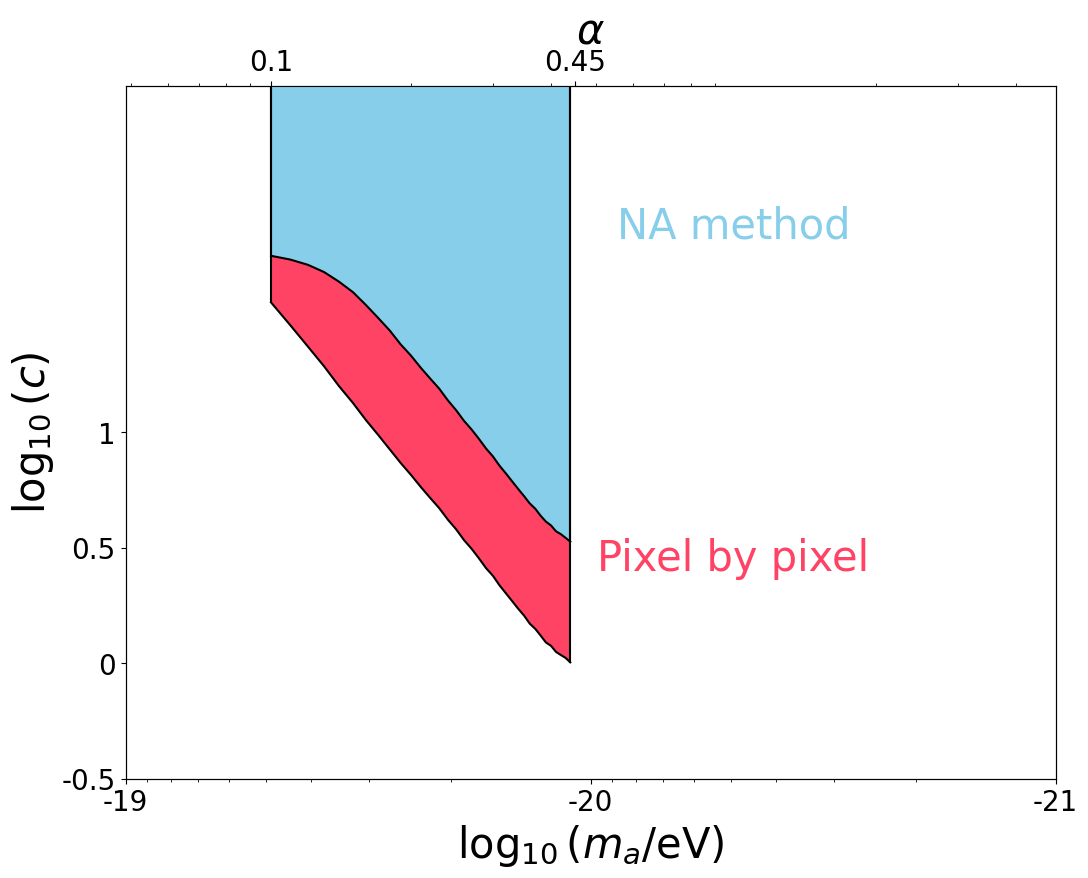

In [256]:
plt.clf()
fig,ax = plt.subplots(figsize=(12,9))
ax.set_xscale('log')
ax2 = ax.twiny()
ax2.set_xscale('log')
ax.set_ylim(-0.5,2.5)
ax.set_yticks([-0.5,0,0.5,1])
ax.set_yticklabels(['-0.5','0','0.5','1'],size=20)
ax.set_ylabel('$\log_{10}(c)$',size=30)
ax2.set_xticks([0.1,0.45])
ax2.set_xticklabels(['0.1','0.45'],size=20)
ax2.set_xlabel(r'$ \alpha $',size=30)
ax2.set_xlim(0.0486495,4.86495)
ax.set_xlim(1E-19, 1E-21)
ax.set_xticks([1E-21,1E-20,1E-19])
ax.set_xticklabels(['-21','-20','-19'],size=20)
ax.set_xlabel('$\log_{10}(m_a/\mathrm{eV})$',size=30)
temp = np.load('new_static/l_cor_1d.npz')
x1 = temp['omegas']
y1 = temp['cuts']
yarray1 = deepcopy(y1)
temp = np.load('M_all/new_static/l_cor_dyn_obs.npz')
x2 = temp['omegas']
y2 = temp['cuts']
# y2[-2] = -1.09
# y2[-1] = -1.12
yarray2 = deepcopy(y2)


# for i in range(1,len(y2)-1):
#     yarray1[i] = (y1[i-1]+y1[i]+y1[i+1])/3.
#     yarray2[i] = (y2[i-1]+y2[i]+y2[i+1])/3.

ax2.plot(x1,yarray1,'black')
ax2.plot([np.max(x1),np.max(x1)],[yarray1[-1],6],'black')
ax2.plot([np.min(x1),np.min(x1)],[yarray1[0],6],'black')
ax2.plot(x2,yarray2,'black')
ax2.plot([np.max(x1),np.max(x1)],[yarray2[-1],6],'black')
ax2.plot([np.min(x1),np.min(x1)],[yarray2[0],6],'black')
xcolor = ['SkyBlue','#C8C8A9','#FE4365']
ax2.fill_between(x1,yarray1, 3,ls='-',lw=2,fc = xcolor[0],alpha=1)
ax2.fill_between(x1,yarray2, yarray1,ls='-',lw=2,fc = xcolor[2],alpha=1)
plt.annotate('NA method',xy=(0.78,0.78),xycoords='axes fraction',ha='right',size=30,color = xcolor[0])
plt.annotate('Pixel by pixel',xy=(0.8,0.3),xycoords='axes fraction',ha='right',size=30,color = xcolor[2])
plt.savefig(f'new_static/contract.pdf',dpi=600)

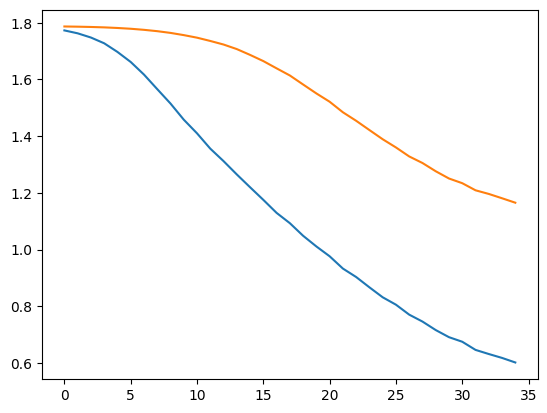

In [170]:
plt.plot(final_cut1["cuts"])
plt.plot(final_cut2["cuts"])

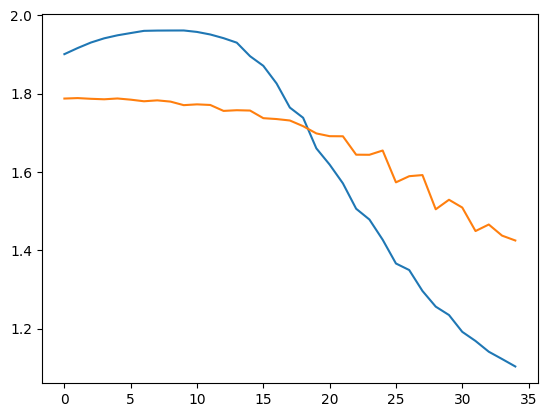

In [160]:
plt.plot(final_cut1["cuts"])
plt.plot(final_cut2["cuts"])

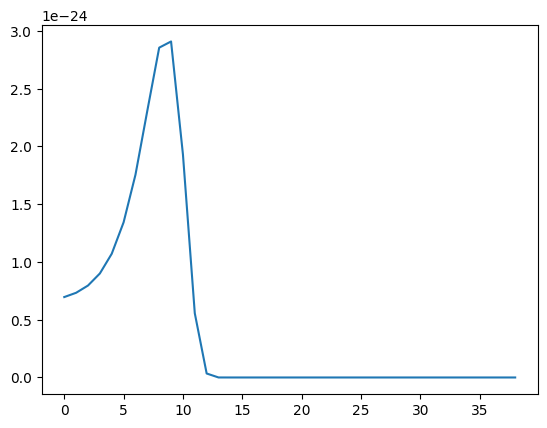

In [32]:
plt.plot(np.diff(prgagg))

In [101]:
final_cut[34]-final_cut[0]

np.float64(-1.3126400088088257)

In [ ]:
All_data=np.load(f'./EHT-Imaging/101_all_data.npy')
theta_data101=0.5*np.arctan2(np.mean(All_data[:,:,:,2],axis=0),np.mean(All_data[:,:,:,1],axis=0)) # rad

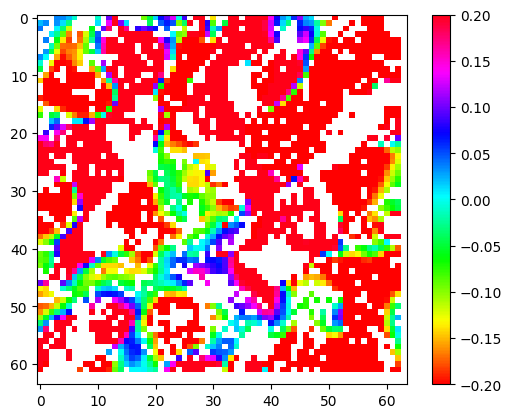

In [158]:
plt.imshow(CircleCalc.circle_sub_evpa(theta_mean[1],theta_mean[0]),cmap='hsv')
plt.colorbar()
plt.clim(-0.2,0.2)

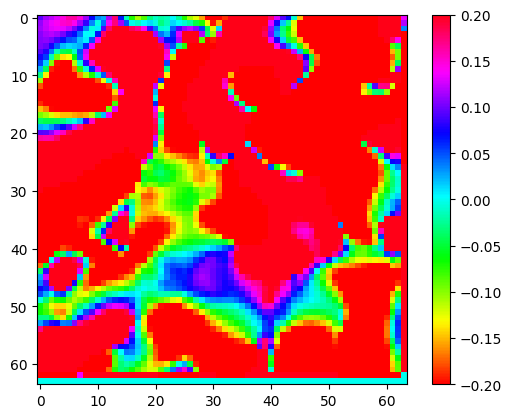

In [157]:
plt.imshow(CircleCalc.circle_sub_evpa(theta_data96,theta_data95),cmap='hsv')
plt.colorbar()
plt.clim(-0.2,0.2)

In [136]:
jj=theta_mean[1]-theta_mean[0]
jj[np.sqrt(theta_std[1]*theta_std[1]+theta_std[0]*theta_std[0])>0.3]=np.nan

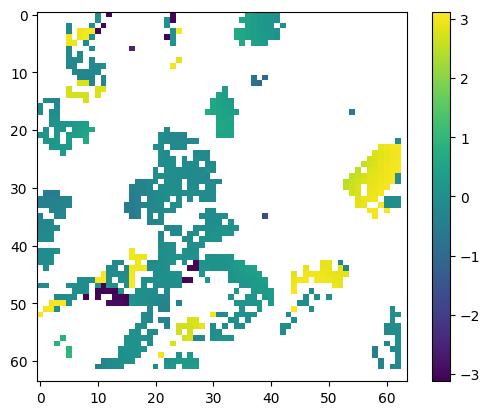

In [137]:
plt.imshow(jj)
plt.colorbar()
# plt.clim(-0.2,0.2)

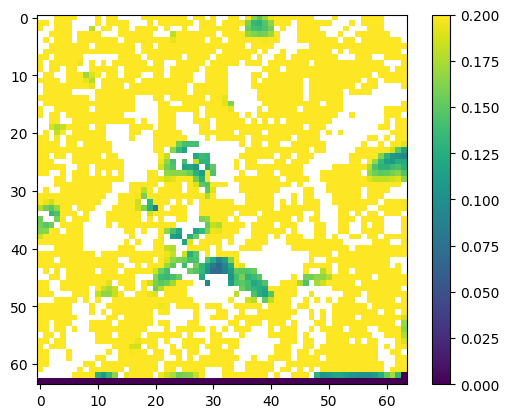

In [ ]:
plt.imshow(np.sqrt(theta_std[1]*theta_std[1]+theta_std[0]*theta_std[0]))
plt.colorbar()
plt.clim(0,0.2)

In [107]:
cor_std_good[0,1,1]

np.float64(0.4512943525439286)

In [108]:
(np.asarray([np.diag(Delta_std[0]),np.diag(Delta_std[1])])[:,goodsetrow,goodsetcol])[0].min()

np.float64(0.0)

In [110]:
jj=(np.asarray([np.diag(Delta_std[0]),np.diag(Delta_std[1])])[:,goodsetrow,goodsetcol])

In [112]:
np.array([jj[1,i,i] for i in range(237)]).min()

np.float64(0.11598372425616639)

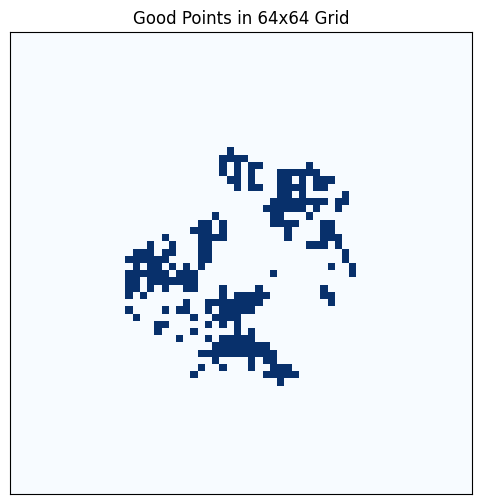

In [130]:
grid = np.zeros((64, 64))

# 把 goodset 里的点设为 1
for num in goodset:
    x, y = divmod(num, 64)
    grid[x, y] = 1

# 画图
plt.figure(figsize=(6, 6))
plt.imshow(grid, cmap='Blues', origin='upper')  # 颜色用蓝色
plt.xticks([])
plt.yticks([])
plt.title("Good Points in 64x64 Grid")
plt.show()

In [109]:
[cor_std+cor_grmhd+tmpCorAxion[i]*(gagg[g]*gagg[g]) for i in range(16) ]

[array([[[nan, nan, nan, ..., nan, nan, nan],
         [nan, nan, nan, ..., nan, nan, nan],
         [nan, nan, nan, ..., nan, nan, nan],
         ...,
         [nan, nan, nan, ..., nan,  0.,  0.],
         [nan, nan, nan, ...,  0., nan,  0.],
         [nan, nan, nan, ...,  0.,  0., nan]],
 
        [[nan,  0.,  0., ..., nan, nan,  0.],
         [ 0., nan,  0., ..., nan, nan,  0.],
         [ 0.,  0., nan, ..., nan, nan,  0.],
         ...,
         [nan, nan, nan, ..., nan, nan, nan],
         [nan, nan, nan, ..., nan, nan, nan],
         [ 0.,  0.,  0., ..., nan, nan, nan]]]),
 array([[[nan, nan, nan, ..., nan, nan, nan],
         [nan, nan, nan, ..., nan, nan, nan],
         [nan, nan, nan, ..., nan, nan, nan],
         ...,
         [nan, nan, nan, ..., nan,  0.,  0.],
         [nan, nan, nan, ...,  0., nan,  0.],
         [nan, nan, nan, ...,  0.,  0., nan]],
 
        [[nan,  0.,  0., ..., nan, nan,  0.],
         [ 0., nan,  0., ..., nan, nan,  0.],
         [ 0.,  0., nan, ...,

In [83]:
final_cut

[np.float64(1.501703368559929),
 np.float64(1.4906423571358534),
 np.float64(1.4007462096465821),
 np.float64(1.2690943382366104),
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0]

In [93]:
theta_data_1d_786[theta_data_1d_786>np.pi/2]-=np.pi
theta_data_1d_786[theta_data_1d_786<-np.pi/2]+=np.pi

In [103]:
np.save("Plot/theta_data_1d_786_4",theta_data_1d_786)